# Question 5: SNAP enrollment and food shelf use

The ask: SNAP gives a household money to buy food. A food shelf gives a household food directly. Do the two move together, or does one replace the other? The SNAP benefits may change from time-to-time, what happens to food shelf activity when the SNAP benefits change? Does the relationship between SNAP benefits and food shelf activity differ across locations? Understanding the nature of this relationship helps The Food Group highlight the importance of SNAP to lawmakers and in turn helps them make better informed decisions.

**Required:** a public SNAP source joined to the food-shelf data, with **source, grain, and publication lag** stated (see Datasets below).

### How this notebook answers each part
| Sub-question | What we measure | Section |
|---|---|---|
| **Q5-A. Move together or substitute?** | (i) **Across counties:** SNAP participation rate vs food-shelf visit and pound rates per 1,000 residents. (ii) **Over time:** statewide SNAP benefit per person vs food-shelf activity. (iii) **Within counties:** fixed-effects check, used as robustness only | §5.2, §5.5, §6.5 Spec B; §5.3, §8.1 |
| **Q5-B. What happens when benefits change?** | Natural experiment: end of SNAP **Emergency Allotments** (Apr 2023 in accounting months). Statewide dollars lost; interrupted time series with a food-price control, placebo break test and persistence check; county dose-response per SNAP person and per resident; the 2026 enrollment drop | §6.1–§6.6 |
| **Q5-C. Does it differ across locations?** | Metro (7-county Twin Cities) vs Greater Minnesota; county-by-county response to the EA cut; small vs mid vs large counties | §7.1–§7.3 |

**Outcome metrics (reported separately, per the brief):** visits (`HouseholdsReg`), pounds distributed (`PoundsReg`), individuals served (`IndividualsReg`).

Datasets:
| File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly food-shelf visits (households), pounds distributed, individuals served |
| `Organization.xlsx` | Organization | Partner master file: type, status, location (`block_geoid` → county) |
| `Q5-snap-dashboard-data_thru_Jul2026.xlsx` | County/Tribe × month (88 units, Jan 2016 – Jul 2026) | Monthly SNAP cases, persons, and net benefits issued (federal SNAP + state MFIP/MFAP food portions); joined to food-shelf data on county × month |
| `Q4-FRED-CPI-Midwest_thru_Jul2026.xlsx` (from Q4) | Midwest × month (through Jul 2026) | Food-at-home price index; controls for food inflation when testing the SNAP benefit cut |
| `co-est2025-alldata.csv` | County × year (July 1) | Resident population; turns counts into rates per 1,000 residents and SNAP dollars lost per resident |
| `Q5-snap-dashboard-statewide-totals_thru_Jul2026.xlsx` | Statewide × month (Jan 2016 – Jul 2026) | Statewide SNAP totals for trend charts and to check the county sums |

**SNAP source — grain & publication lag**
* **Grain:** county or Tribal Nation × month. Report month is the **accounting month** (when benefits were paid), net of cancelled payments.
* **Publication lag:** published monthly, about **1 month** after the report month (checked when accessed on **2026-09-28**). Only **Jan 2016 – Jul 2026** is used; later rows were removed before analysis, per competition rules.
* **Why this source:** monthly and county-level (joins directly to food-shelf county × month), back to 2016, covers the Emergency Allotment end. Chosen over the DHS calendar-year reports, which are annual summaries of the same counts.

Sources:
- Minnesota Department of Children, Youth, and Families (DCYF). *SNAP Food Assistance Data Dashboard — county/Tribe monthly data* (DCYF download `snap-dashboard-data-through-august-2026.xlsx`; rows after Jul 2026 removed per competition rules → `Q5-snap-dashboard-data_thru_Jul2026.xlsx`), monthly by county or Tribal Nation (accounting month), Jan 2016 – Jul 2026 used; household cases, persons, and food benefits issued, cancelled, and net by funding source (federal SNAP, state MFAP, MFIP food portion). https://dcyf.mn.gov/snap-food-assistance-minnesota (accessed 2026-09-28)
- Minnesota Department of Children, Youth, and Families (DCYF). *SNAP Food Assistance Data Dashboard — statewide totals* (DCYF download `snap-dashboard-statewide-totals-through-august-2026.xlsx`; rows after Jul 2026 removed per competition rules → `Q5-snap-dashboard-statewide-totals_thru_Jul2026.xlsx`), monthly, statewide, Jan 2016 – Jul 2026 used; same measures as above. https://dcyf.mn.gov/snap-food-assistance-minnesota (accessed 2026-09-28)
- U.S. Bureau of Labor Statistics, via Federal Reserve Bank of St. Louis (FRED). *Consumer Price Index for All Urban Consumers: Food at Home in Midwest Urban* (`CUUR0200SAF11`), monthly, not seasonally adjusted, index 1982–84=100; rows after Jul 2026 removed per competition rules (`Q4-FRED-CPI-Midwest_thru_Jul2026.xlsx`). https://fred.stlouisfed.org/series/CUUR0200SAF11 (data updated 2026-09-11; accessed 2026-09-28). Publication lag: BLS releases each month's CPI about two weeks after the month ends. Why this source: there is no Minnesota food-at-home CPI; the Midwest urban series is the closest regional match and is the same series used in Q4, so the two questions use one price measure.
- U.S. Census Bureau, Population Estimates Program. *County Population Totals and Components of Change: 2020–2025* (Vintage 2025, `co-est2025-alldata.csv`), annual July 1 resident population by county; Minnesota's 87 counties used. https://www.census.gov/data/tables/time-series/demo/popest/2020s-counties-total.html (accessed 2026-10-09). Publication lag: Vintage 2025 county totals were released in March 2026, about 8 months after the July 1, 2025 reference date. Why this source: it is the latest official annual county estimate and covers every year of the food-shelf window; ACS 5-year estimates are multi-year averages and lag further.

## 1. Setup

### 1.1 Libraries and chart style

> **Purpose:** Load the packages used in every step and set one chart style (fixed color order, light grid) so all Q5 charts look consistent on the slides.

In [35]:
# !pip install -q statsmodels openpyxl   # uncomment if needed in Colab
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# Chart palette (fixed order; validated categorical slots)
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
GRID = "#e6e5e1"
plt.rcParams.update({
    "figure.figsize": (11, 4.5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "lines.linewidth": 2,
    "axes.titleweight": "bold", "axes.titlesize": 12,
})

> **What this result means**
- No output. `statsmodels` runs the regressions; the four colors are always used in the same order (visits → pounds → SNAP persons → SNAP benefits).

### 1.2 Load the four files

> **Purpose:** Read the two Food Group files and the two DCYF SNAP files, and confirm their size and columns before any cleaning.

In [36]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/MinneMUDAC 26 for BU/Suji/Data/Q5"

FS_PATH         = f"{DATA_DIR}/org_FSStats.xlsx"
ORG_PATH        = f"{DATA_DIR}/Organization.xlsx"
SNAP_PATH       = f"{DATA_DIR}/Q5-snap-dashboard-data_thru_Jul2026.xlsx"              # trimmed to Jul 2026 (competition rule)
SNAP_STATE_PATH = f"{DATA_DIR}/Q5-snap-dashboard-statewide-totals_thru_Jul2026.xlsx"  # trimmed to Jul 2026 (competition rule)

fs_raw   = pd.read_excel(FS_PATH)
org_raw  = pd.read_excel(ORG_PATH)
snap_raw = pd.read_excel(SNAP_PATH, parse_dates=["Report_Month"])
snap_st  = pd.read_excel(SNAP_STATE_PATH, parse_dates=["Report_Month"])
for _df in (snap_raw, snap_st):
    assert _df["Report_Month"].max() <= pd.Timestamp("2026-07-01"), "SNAP file contains months after Jul 2026"

for name, df in [("org_FSStats", fs_raw), ("Organization", org_raw),
                 ("SNAP county", snap_raw), ("SNAP statewide", snap_st)]:
    print(f"{name:15s} {df.shape}")
    print("   ", list(df.columns)[:30], "\n")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
org_FSStats     (28287, 58)
    ['__ID', '_id_site', '_Year', '_Month', 'DateForSearch', 'zzCreationTS', 'zzModificationTS', 'AdultsReg', 'ChildrenReg', 'HouseholdsReg', 'IndividualsReg', 'Meals', 'Misc', 'People', 'PoundsReg', 'SeniorsReg', 'Snacks', 'UniqueVisitsReg', 'County', 'FederalDistrict', 'StateDistrict', 'FoodBank', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra'] 

Organization    (1202, 68)
    ['__ID', 'CreateTime', 'zzCreationTS', 'zzModificationTS', '_id_type', 'City', 'State', 'Zip', 'MailCity', 'MailState', 'MailZip', 'Eligibility', 'Conditions', 'MarketSeasons', 'zcountDaysOperations', 'Region', 'SuperRegion', 'County', 'StateDistrict', 'FederalDistrict', 'DistrictSection', 'AgencyType', '_id_subtype', 'AgencySubType', 'isFoodBank', 'isAgency', 'isDis

> **What this result means**
- `org_FSStats` has **28,287 site-month rows** and 58 columns. Most columns are deprecated; we only use the `Reg` metrics, `_id_site`, `_Year`, `_Month`.
- `Organization` has **1,202 partner records**. It supplies type, status and location (`block_geoid`).
- The SNAP county file has **11,121 rows** (88 county/Tribe units × Jan 2016 – Jul 2026). The statewide file has **127 months**. Both files were trimmed to Jul 2026 before loading (no August data, per competition rules).

### 1.3 Analysis settings

> **Purpose:** Keep every judgment call in one place (join key, food-shelf filter, error and outlier rules, balanced-panel threshold, Tribal handling, EA date) so it can be changed and re-run, and so each choice can be defended to judges.

In [37]:

# --- Food-shelf columns (confirmed in the Data Dictionary) ---
METRICS = {"HouseholdsReg": "visits", "PoundsReg": "pounds", "IndividualsReg": "individuals"}

# --- Join key (verified: org_FSStats._id_site matches Organization.__ID for 99.9% of rows) ---
FS_KEY     = "_id_site"   # site ID in org_FSStats (NOT __ID, which is the stats-row ID)
ORG_ID_COL = "__ID"       # organization ID in Organization

# --- Food-shelf filter ---
# Meal programs serve prepared meals, not grocery visits; farmers markets and the food bank are not food shelves.
# The same thing is labelled differently in the two tables, so all spellings are listed.
NON_SHELF_TYPES = ["Meal Program", "Meal Programs", "On-Site Meal Programs", "Farmers Market", "Food Bank"]
# A site is dropped if Organization types it as non-shelf OR most of its monthly records do
NON_SHELF_SITE_SHARE = 0.5

# --- Metric errors and outliers ---
HH_INDIV_ERROR_RATIO = 2.0            # HouseholdsReg / IndividualsReg >= this is impossible
ERROR_POLICY = "null_individuals"     # "null_individuals" | "null_both" | "keep"
SPIKE_MULTIPLE = 10                   # a site-month > 10x that site's own median is treated as a typo

# --- Panel construction ---
MIN_REPORT_SHARE = 0.9                # balanced panel: sites reporting in >= 90% of months
MIN_TRAILING_COVERAGE = 0.8           # drop trailing months where < 80% of usual sites have reported

# --- Geography ---
TRIBE_POLICY = "fold"                 # Tribal SNAP units: "fold" into the main county, or "drop"

# --- Policy date (accounting month). Last EA issuance was for Feb 2023 but PAID in March,
#     so the first month without EA in the dashboard is April 2023 (verified in §6.1). ---
EA_FIRST_POST = pd.Timestamp("2023-04-01")


> **What this result means**
- No output. Two settings were set after checking the raw data: the **food-shelf filter** checks meal programs under every label (§2.2), and the **spike rule** removes single-month typos (§2.5).

### 1.4 Join-key check

> **Purpose:** Prove that `org_FSStats` and `Organization` are joined on the right column. A wrong key silently attaches the wrong county and type to every site.

In [38]:
def norm_key(s):
    # Compare IDs as clean strings so 123 and 123.0 match
    return s.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)

fs_ids  = norm_key(fs_raw[FS_KEY])
org_ids = norm_key(org_raw[ORG_ID_COL])
print(f"{FS_KEY} → Organization.{ORG_ID_COL}: match rate {fs_ids.isin(set(org_ids.dropna())).mean():.1%}")
print(f"Organization.{ORG_ID_COL} unique: {org_ids.dropna().is_unique}")
# Diagnostic (2026-10-06): __ID↔__ID matched only by coincidence (stats-row ID), _id_bank / id_agency are
# the supplying food bank / parent agency, so _id_site is the correct site-level key.

_id_site → Organization.__ID: match rate 99.9%
Organization.__ID unique: True


> **What this result means**
- **99.9%** of food-shelf rows find their site in `Organization`, and the Organization ID is unique, so `_id_site → __ID` is a clean many-to-one join.
- The earlier auto-detected key (`__ID` on both sides) matched only by coincidence, because `org_FSStats.__ID` is a row number. `_id_bank` and `id_agency` point to the supplying food bank and the parent agency, not the site.

### 1.5 Load supporting public data (CPI and population)

> **Purpose:** Load the two supporting public sources. The **food-at-home CPI** (already used in Q4) lets us separate the SNAP cut from food inflation. **County population** lets us compare counties fairly (rates per 1,000 residents) and measure how much SNAP money each county lost **per resident**, which varies far more than the loss per SNAP recipient.

In [39]:
Q4_DIR   = "/content/drive/MyDrive/MinneMUDAC 26 for BU/Suji/Data/Q4"
CPI_PATH = f"{Q4_DIR}/Q4-FRED-CPI-Midwest_thru_Jul2026.xlsx"   # trimmed to Jul 2026 (no August data, competition rule)
POP_PATH = f"{DATA_DIR}/co-est2025-alldata.csv"     # put the Census file in the Q5 data folder

cpi = (pd.read_excel(CPI_PATH, sheet_name="Monthly")
         .rename(columns={"observation_date": "month", "CUUR0200SAF11": "cpi_food_home"})
         .dropna())
cpi["month"] = pd.to_datetime(cpi["month"]).dt.to_period("M").dt.to_timestamp()
cpi["cpi_food_home"] = pd.to_numeric(cpi["cpi_food_home"], errors="coerce")
assert cpi["month"].max() <= pd.Timestamp("2026-07-01"), "CPI file contains months after Jul 2026"
print(f"CPI food at home (Midwest): {cpi['month'].min():%Y-%m} → {cpi['month'].max():%Y-%m}")
check_months = pd.to_datetime(["2022-01-01", "2023-01-01", "2023-04-01", "2024-04-01"]).append(pd.DatetimeIndex([cpi["month"].max()]))
print(cpi.set_index("month").loc[check_months, "cpi_food_home"].round(1).to_string())

pop_raw = pd.read_csv(POP_PATH, encoding="latin-1")   # the Census file is not UTF-8
pop_mn_raw = pop_raw[(pop_raw["STATE"] == 27) & (pop_raw["SUMLEV"] == 50)]
print(f"\nMinnesota counties in Census file: {len(pop_mn_raw)} | "
      f"years: {[c[-4:] for c in pop_raw.columns if c.startswith('POPESTIMATE')]}")
print(f"Statewide 2025 population: {pop_mn_raw['POPESTIMATE2025'].sum():,}")

CPI food at home (Midwest): 1977-12 → 2026-07
2022-01-01    255.4
2023-01-01    285.7
2023-04-01    286.5
2024-04-01    289.1
2026-07-01    302.5

Minnesota counties in Census file: 87 | years: ['2020', '2021', '2022', '2023', '2024', '2025']
Statewide 2025 population: 5,830,405


> **What this result means**
- The CPI file covers **Dec 1977 – Jul 2026**, which overlaps the whole food-shelf period. Food-at-home prices rose about **12% during 2022** (≈255 → ≈286), then stayed **almost flat** after April 2023 (≈286.5 → ≈289 a year later). The EA cut happened **after** the big price jump.
- The Census file has all **87 Minnesota counties**, with July 1 estimates for **2020–2025**. Counties are matched by FIPS code, so spelling differences ("Lake of the Woods" vs the dashboard's "Lake of Woods") do not matter. Months in 2026 use the 2025 estimate.

## 2. Clean the food-shelf data
Rules from the Data Dictionary and from checking the raw data:
1. Use only the live **Reg** fields; Extra/Produce/Holiday/Total fields are deprecated.
2. Keep **food shelves** only.
3. Do **not** drop inactive sites from history; only drop months after their `InactiveDate`.
4. Fix impossible values: `HouseholdsReg > IndividualsReg`, negatives, one-sided zeros, and single-month spikes.
5. Recompute ratio columns instead of trusting the stored ones.

### 2.1 Attach organization attributes

> **Purpose:** Give every site-month its site's type, status and location from the master record, build a clean `month` column, and remove duplicate site-months.

In [40]:
fs  = fs_raw.copy()
org = org_raw.copy()
fs["_key"]  = norm_key(fs[FS_KEY])
org["_key"] = norm_key(org[ORG_ID_COL])

# Month from _Year/_Month (DateForSearch / zz*TS are system fields)
fs["month"] = pd.to_datetime(dict(year=pd.to_numeric(fs["_Year"], errors="coerce"),
                                  month=pd.to_numeric(fs["_Month"], errors="coerce"), day=1),
                             errors="coerce")
print(f"Unparseable months: {fs['month'].isna().sum():,}")
fs = fs.dropna(subset=["month"])

# Duplicate site-months: keep the most recently modified record
dup = fs.duplicated(["_key", "month"], keep=False)
print(f"Duplicate site-month rows: {dup.sum():,}")
if dup.any():
    fs = (fs.sort_values("zzModificationTS")
            .drop_duplicates(["_key", "month"], keep="last"))

org_keep = ["_key", "AgencyType", "AgencySubType", "isActive", "ActiveInactive",
            "InactiveDate", "block_geoid", "County"]
org = org[[c for c in org_keep if c in org.columns]].drop_duplicates("_key")

# AgencyType and County exist in both tables: keep both with suffixes
fs = fs.merge(org, on="_key", how="left", suffixes=("_fs", "_org"),
              validate="many_to_one", indicator=True)
print(f"Join match rate: {(fs['_merge'] == 'both').mean():.1%}")
fs = fs.drop(columns="_merge")
ORG_KEY = "_key"   # later cells group by this

# One county-name column for the geography fallback: master record first, stats record second
fs["County"] = fs["County_org"].fillna(fs["County_fs"])
county_name_cols = ["County"]

for col in ["AgencyType_fs", "AgencyType_org", "AgencySubType"]:
    if col in fs.columns:
        print(f"\n{col}:\n{fs[col].value_counts(dropna=False).to_string()}")

Unparseable months: 26
Duplicate site-month rows: 87
Join match rate: 99.9%

AgencyType_fs:
AgencyType_fs
Brick and Mortar Site      14692
Food Shelf                  7401
Outreach Program            2476
Meal Program                1593
On-Site Meal Programs       1039
Mobile                       354
Tribal Program               222
College Campus Program       165
NaN                          138
Meal Programs                 89
Other Non-Profit              22
Agency or Tribal Nation       17
Brick and Mortar Sites         9

AgencyType_org:
AgencyType_org
Brick and Mortar Site      21328
Outreach Program            3514
Meal Program                2699
Tribal Program               267
College Campus Program       265
NaN                          130
Agency or Tribal Nation       14

AgencySubType:
AgencySubType
NaN                    26046
Mobile                  2134
Pop-up Distribution       37


> **What this result means**
- **26 rows** have no valid year/month and are dropped. **87 duplicate site-months** are reduced to the most recently modified record.
- The join matches **99.9%** of rows.
- The two type columns disagree. `org_FSStats` calls 7,401 rows **"Food Shelf"** that Organization calls "Brick and Mortar Site", and it uses **three different labels for meal programs** (Meal Program, On-Site Meal Programs, Meal Programs). This is why §2.2 now checks both columns.
- `AgencySubType` is mostly blank (only Mobile and Pop-up are filled), so it cannot be the main filter.

### 2.2 Filter to food shelves

> **Purpose:** Keep only sites that hand groceries directly to households, which is what Q5 compares with SNAP. Meal programs, farmers markets and the food bank measure something else.

In [41]:
fs["is_non_shelf_fs"] = fs["AgencyType_fs"].isin(NON_SHELF_TYPES)
site_non_shelf_share = fs.groupby(ORG_KEY)["is_non_shelf_fs"].mean()
org_non_shelf = fs.groupby(ORG_KEY)["AgencyType_org"].first().isin(NON_SHELF_TYPES)
drop_sites = site_non_shelf_share.index[(site_non_shelf_share > NON_SHELF_SITE_SHARE) | org_non_shelf]

summary = (fs.assign(dropped=fs[ORG_KEY].isin(drop_sites))
             .groupby(["AgencyType_fs", "dropped"], dropna=False).size().unstack(fill_value=0))
print("Rows by org_FSStats type → kept / dropped")
print(summary.rename(columns={False: "kept", True: "dropped"}).sort_values("kept", ascending=False).to_string())

before_rows, before_sites = len(fs), fs[ORG_KEY].nunique()
fs = fs[~fs[ORG_KEY].isin(drop_sites)].copy()
assert len(fs) > 0, "Filter removed every row: check NON_SHELF_TYPES"
print(f"\nDropped {before_sites - fs[ORG_KEY].nunique():,} sites / {before_rows - len(fs):,} rows")
print(f"Food-shelf rows kept: {len(fs):,} | sites: {fs[ORG_KEY].nunique():,} | "
      f"months: {fs['month'].min():%Y-%m} → {fs['month'].max():%Y-%m}")

Rows by org_FSStats type → kept / dropped
dropped                   kept  dropped
AgencyType_fs                          
Brick and Mortar Site    14692        0
Food Shelf                7401        0
Outreach Program          2476        0
Mobile                     354        0
Tribal Program             222        0
College Campus Program     165        0
NaN                        138        0
Meal Program                22     1571
Other Non-Profit            22        0
Agency or Tribal Nation     17        0
Brick and Mortar Sites       9        0
On-Site Meal Programs        0     1039
Meal Programs                0       89

Dropped 65 sites / 2,699 rows
Food-shelf rows kept: 25,518 | sites: 600 | months: 2022-01 → 2026-07


> **What this result means**
- **65 sites / 2,699 rows dropped** (meal programs). **25,518 rows from 600 sites** remain, from Jan 2022 to Jul 2026.
- Every site that `org_FSStats` labels "On-Site Meal Programs" or "Meal Programs" is already typed "Meal Program" in Organization. The two tables **agree**, which is a useful check on the filter.
- 22 rows labelled "Meal Program" in `org_FSStats` are kept because their site is a food shelf in Organization and in most of its own records.

### 2.3 Drop months after a site closed

> **Purpose:** Remove records dated after a site's `InactiveDate` (late or test entries) without deleting the site's real history. Dropping every inactive site would erase food shelves that closed in 2024 from the 2022–23 data and bias the trend.

In [42]:
if "InactiveDate" in fs.columns:
    inact = pd.to_datetime(fs["InactiveDate"], errors="coerce")
    after_close = inact.notna() & (fs["month"] > inact)
    print(f"Rows after InactiveDate dropped: {after_close.sum():,}")
    fs = fs[~after_close].copy()

Rows after InactiveDate dropped: 30


> **What this result means**
- Only **30 rows** fall after a closing date, so status filtering barely affects the data. History from sites that later closed is kept.

### 2.4 Not-reported months and Households > Individuals errors

> **Purpose:** Separate "site did not report" from "site served zero people", and fix the rows that break the rule Individuals ≥ Households (a household has at least one person).

In [43]:
for c in METRICS:
    fs[c] = pd.to_numeric(fs[c], errors="coerce")

not_reported = (fs["HouseholdsReg"].fillna(0) == 0) & (fs["PoundsReg"].fillna(0) == 0)
fs.loc[not_reported, list(METRICS)] = np.nan

ratio = fs["HouseholdsReg"] / fs["IndividualsReg"].replace(0, np.nan)
fs["flag_hh_gt_indiv"] = ratio >= HH_INDIV_ERROR_RATIO
print(f"Not-reported site-months: {not_reported.sum():,}")
print(f"Flagged HH>Indiv errors (ratio >= {HH_INDIV_ERROR_RATIO}): {fs['flag_hh_gt_indiv'].sum():,}")

if ERROR_POLICY == "null_individuals":
    fs.loc[fs["flag_hh_gt_indiv"], "IndividualsReg"] = np.nan
elif ERROR_POLICY == "null_both":
    fs.loc[fs["flag_hh_gt_indiv"], ["IndividualsReg", "HouseholdsReg"]] = np.nan

# Recompute ratios from cleaned values (do not use stored PoundsPerHH etc.)
# ±inf ratios are expected at this step (fixed in §2.5); silence the NumPy warning they trigger in describe()
import warnings
warnings.filterwarnings("ignore", message="invalid value encountered in reduce", category=RuntimeWarning)
fs["pounds_per_hh"] = fs["PoundsReg"] / fs["HouseholdsReg"]
fs["indiv_per_hh"]  = fs["IndividualsReg"] / fs["HouseholdsReg"]
fs[list(METRICS) + ["pounds_per_hh", "indiv_per_hh"]].describe().T

Not-reported site-months: 1,016
Flagged HH>Indiv errors (ratio >= 2.0): 22


,count,mean,std,min,25%,50%,75%,max
HouseholdsReg,24405.0,5.135334e+02,2180.126903,0.0,63.000000,153.000000,458.000000,273385.0
PoundsReg,24398.0,2.697342e+04,54484.192229,-4415.0,3280.000000,8261.000000,26105.750000,994394.0
IndividualsReg,24390.0,1.513769e+03,4075.857038,0.0,157.000000,422.000000,1279.000000,89669.0
pounds_per_hh,24331.0,NaN,NaN,-inf,38.562562,56.909091,79.064892,inf
indiv_per_hh,24374.0,inf,NaN,0.0,2.222222,2.733333,3.323302,inf


> **What this result means**
- **1,016 site-months** have zero visits and zero pounds. These are treated as *not reported*, not as zero demand.
- **22 rows** have Households at least 2× Individuals. Their Individuals value is set to missing (Individuals is self-reported); Households and Pounds are kept.
- The summary table shows problems this step does not fix. **Households max = 273,385** for one site-month (median 153), **Pounds has negative values** (min −4,415), and the ratio columns hit **±inf** because some months have 0 households but positive pounds. These distort every statewide total and regression downstream, so §2.5 was added.

### 2.5 Invalid values and single-month spikes

> **Purpose:** Remove values that cannot be real before aggregating: negatives, one-sided zeros, and single-month typos such as an extra digit. Each site is compared with its own median, so a small rural shelf and a large metro shelf are judged on their own scale.

In [44]:
M = list(METRICS)

# 1) Negative counts or pounds are impossible
neg = fs[M] < 0
fs[M] = fs[M].mask(neg)

# 2) One-sided zeros: 0 households but food went out (or the reverse) = incomplete entry
hh0 = (fs["HouseholdsReg"] == 0) & (fs["PoundsReg"] > 0)
lb0 = (fs["PoundsReg"] == 0) & (fs["HouseholdsReg"] > 0)
fs.loc[hh0, ["HouseholdsReg", "IndividualsReg"]] = np.nan
fs.loc[lb0, "PoundsReg"] = np.nan

# 3) Single-month spikes: > SPIKE_MULTIPLE x the site's own median
site_med = fs.groupby(ORG_KEY)[M].transform("median")
spike = (fs[M] > SPIKE_MULTIPLE * site_med) & (site_med > 0)
top = (fs.loc[spike["HouseholdsReg"], [ORG_KEY, "month", "HouseholdsReg"]]
         .assign(site_median=site_med.loc[spike["HouseholdsReg"], "HouseholdsReg"])
         .sort_values("HouseholdsReg", ascending=False).head(10))
fs[M] = fs[M].mask(spike)

print(f"Negative values removed: {neg.sum().to_dict()}")
print(f"0 households but pounds > 0: {hh0.sum():,} | 0 pounds but households > 0: {lb0.sum():,}")
print(f"Spikes > {SPIKE_MULTIPLE}x site median: {spike.sum().to_dict()}")
print("\nLargest household spikes removed:"); print(top.to_string(index=False))

# 4) Carry-forward check: identical numbers to the previous month (possible copy-paste reporting)
fs = fs.sort_values([ORG_KEY, "month"])
same_as_prev = (fs.groupby(ORG_KEY)[M].shift(1) == fs[M]).all(axis=1) & fs[M].notna().all(axis=1)
fs["flag_carry_forward"] = same_as_prev
print(f"\nSite-months identical to the previous month on all 3 metrics: {same_as_prev.sum():,} "
      f"({same_as_prev.mean():.1%}) — flagged, not removed")

# Recompute ratios from the cleaned values
fs["pounds_per_hh"] = fs["PoundsReg"] / fs["HouseholdsReg"]
fs["indiv_per_hh"]  = fs["IndividualsReg"] / fs["HouseholdsReg"]
fs[M + ["pounds_per_hh", "indiv_per_hh"]].describe().T.round(1)

Negative values removed: {'HouseholdsReg': 0, 'PoundsReg': 4, 'IndividualsReg': 0}
0 households but pounds > 0: 7 | 0 pounds but households > 0: 13
Spikes > 10x site median: {'HouseholdsReg': 35, 'PoundsReg': 19, 'IndividualsReg': 17}

Largest household spikes removed:
 _key      month  HouseholdsReg  site_median
 1197 2023-07-01       273385.0        434.0
 1304 2025-03-01        83909.0       2708.0
 1417 2025-11-01         6670.0         78.0
 1083 2024-11-01         4203.0        400.0
15306 2024-04-01         3257.0         64.5
 1245 2023-06-01         2247.0        220.0
14674 2025-04-01         1688.0         96.0
 1277 2025-07-01         1590.0         22.0
15309 2026-02-01         1519.0         86.0
15309 2026-04-01         1367.0         86.0

Site-months identical to the previous month on all 3 metrics: 218 (0.9%) — flagged, not removed


,count,mean,std,min,25%,50%,75%,max
HouseholdsReg,24363.0,498.1,1190.0,0.0,63.0,152.0,456.0,21382.0
PoundsReg,24362.0,26966.6,54481.2,12.0,3284.2,8261.0,26093.5,994394.0
IndividualsReg,24366.0,1511.7,4074.2,0.0,157.0,421.0,1277.0,89669.0
pounds_per_hh,24259.0,62.9,44.9,0.3,38.6,57.0,79.0,2164.0
indiv_per_hh,24329.0,2.9,1.4,0.0,2.2,2.7,3.3,100.0


> **What this result means**
- **Removed:** 4 negative pounds, 7 months with 0 households but food distributed, 13 with 0 pounds but households served, and **35 / 19 / 17 single-month spikes** (households / pounds / individuals).
- The worst spike was **273,385 households** at a site whose usual month is 434 (Jul 2023), likely a typo with extra digits. Left in, it would create a false July 2023 jump in the statewide charts.
- After cleaning: Households max **21,382** (a large site, still plausible), Pounds min **12** (no negatives), and **no more ±inf** ratios. The medians are realistic: **57 lb per visit** and **2.7 people per household**.
- **218 site-months (0.9%)** repeat the previous month exactly (e.g. Aitkin, Jan–Feb 2022). This is small enough to keep; mention it as a reporting caveat.

## 3. Geography: map each site to a SNAP unit

### 3.1 County → SNAP-unit crosswalk

> **Purpose:** Put both datasets on the same geography. The SNAP dashboard is not a clean 87-county list.

`block_geoid` → first 5 digits = county FIPS → county name.

The SNAP dashboard is not a clean 87-county list, so we build a **`snap_unit`** that both sides share:

| SNAP dashboard entity | What it covers | Food-shelf counties mapped to it |
|---|---|---|
| `MNPrairie` | Dodge + Steele + Waseca consortium | Dodge, Steele, Waseca |
| `Pope` (from Jan 2022) | Western Prairie Human Services = Pope + Grant (Grant series ends Dec 2021) | Pope, Grant |
| `Mille Lacs Band`, `Red Lake Nation`, `White Earth Band` | Tribal Nations administer their own SNAP | `TRIBE_POLICY="fold"` adds them to Mille Lacs, Beltrami, Mahnomen |

All other units are single counties.

In [45]:
# Minnesota counties in DHS county-code order (code n -> FIPS 27 + (2n-1)), spelled as in the SNAP dashboard
MN_COUNTIES = ["Aitkin","Anoka","Becker","Beltrami","Benton","Big Stone","Blue Earth","Brown","Carlton","Carver",
    "Cass","Chippewa","Chisago","Clay","Clearwater","Cook","Cottonwood","Crow Wing","Dakota","Dodge","Douglas",
    "Faribault","Fillmore","Freeborn","Goodhue","Grant","Hennepin","Houston","Hubbard","Isanti","Itasca","Jackson",
    "Kanabec","Kandiyohi","Kittson","Koochiching","Lac Qui Parle","Lake","Lake of Woods","Le Sueur","Lincoln","Lyon",
    "McLeod","Mahnomen","Marshall","Martin","Meeker","Mille Lacs","Morrison","Mower","Murray","Nicollet","Nobles",
    "Norman","Olmsted","Otter Tail","Pennington","Pine","Pipestone","Polk","Pope","Ramsey","Red Lake","Redwood",
    "Renville","Rice","Rock","Roseau","St. Louis","Scott","Sherburne","Sibley","Stearns","Steele","Stevens","Swift",
    "Todd","Traverse","Wabasha","Wadena","Waseca","Washington","Watonwan","Wilkin","Winona","Wright","Yellow Medicine"]
assert len(MN_COUNTIES) == 87
FIPS_TO_COUNTY = {f"27{2*i+1:03d}": name for i, name in enumerate(MN_COUNTIES)}

COUNTY_TO_UNIT = {c: c for c in MN_COUNTIES}
COUNTY_TO_UNIT.update({"Dodge": "MNPrairie", "Steele": "MNPrairie", "Waseca": "MNPrairie", "Grant": "Pope"})
TRIBE_TO_COUNTY = {"Mille Lacs Band": "Mille Lacs", "Red Lake Nation": "Beltrami", "White Earth Band": "Mahnomen"}

METRO7 = {"Anoka", "Carver", "Dakota", "Hennepin", "Ramsey", "Scott", "Washington"}

def norm_county(s):
    # Normalize free-text county names to the dashboard spelling
    s = str(s).strip().replace(" County", "").title()
    fixes = {"Lac Qui Parle": "Lac Qui Parle", "Lake Of The Woods": "Lake of Woods", "Lake Of Woods": "Lake of Woods",
             "Saint Louis": "St. Louis", "St Louis": "St. Louis", "St. Louis": "St. Louis", "Mcleod": "McLeod"}
    return fixes.get(s, s)

geoid = fs["block_geoid"].astype("string").str.replace(r"\.0$", "", regex=True).str.zfill(15) \
        if "block_geoid" in fs.columns else pd.Series(pd.NA, index=fs.index, dtype="string")
fs["county"] = geoid.str[:5].map(FIPS_TO_COUNTY)
if county_name_cols:   # fallback when block_geoid is blank
    fs["county"] = fs["county"].fillna(fs[county_name_cols[0]].map(norm_county))
fs["county"] = fs["county"].where(fs["county"].isin(MN_COUNTIES))
fs["snap_unit"] = fs["county"].map(COUNTY_TO_UNIT)

unmatched = fs.loc[fs["snap_unit"].isna(), ORG_KEY].nunique()
print(f"Sites without a Minnesota county: {unmatched} (excluded from the join)")
fs = fs[fs["snap_unit"].notna()].copy()
print(f"Sites kept: {fs[ORG_KEY].nunique():,} across {fs['snap_unit'].nunique()} SNAP units")

Sites without a Minnesota county: 45 (excluded from the join)
Sites kept: 555 across 83 SNAP units


> **What this result means**
- **45 sites** have no Minnesota county (blank `block_geoid` and no usable county name) and are excluded from the join.
- **555 sites** map to **83 of the 84 SNAP units**. Merging Dodge/Steele/Waseca and Grant/Pope turns 87 counties into 84 units, so almost every unit has at least one reporting food shelf.

## 4. SNAP data and the county × month panel

### 4.1 SNAP variables

> **Purpose:** Turn the DCYF file into the two SNAP measures Q5 needs: how many people are enrolled, and how much food money each person gets. Then check the county file against the statewide file.

* `snap_persons` = `PersonCount` → **enrollment**
* `snap_benefits` = `Total_Net` (federal SNAP + state MFAP + MFIP food portion, net of cancellations). We use the total because `PersonCount` covers all three.
* `benefit_pp` = `snap_benefits / snap_persons` → **benefit generosity**. This is what dropped when Emergency Allotments ended.

In [46]:
snap = snap_raw.rename(columns={"Report_Month": "month", "CountyTribeName": "entity"}).copy()
snap["month"] = snap["month"].dt.to_period("M").dt.to_timestamp()

if TRIBE_POLICY == "fold":
    snap["snap_unit"] = snap["entity"].replace(TRIBE_TO_COUNTY)
else:
    snap = snap[~snap["entity"].isin(TRIBE_TO_COUNTY)]
    snap["snap_unit"] = snap["entity"]

snap = (snap.groupby(["snap_unit", "month"], as_index=False)
            .agg(snap_cases=("CaseCount", "sum"), snap_persons=("PersonCount", "sum"),
                 snap_benefits=("Total_Net", "sum"), snap_fed_net=("SNAP_Federal_Food_Net", "sum")))
snap["benefit_pp"] = snap["snap_benefits"] / snap["snap_persons"]

# Check: county sums vs statewide file
chk = snap.groupby("month")[["snap_persons", "snap_benefits"]].sum().join(
      snap_st.set_index(snap_st["Report_Month"].dt.to_period("M").dt.to_timestamp())[["PersonCount", "Total_Net"]])
gap_persons  = float((chk["snap_persons"] / chk["PersonCount"] - 1).abs().max() * 100)
gap_benefits = float((chk["snap_benefits"] / chk["Total_Net"] - 1).abs().max() * 100)
print(f"Max abs % gap county-sum vs statewide: persons {round(gap_persons, 2)}%, benefits {round(gap_benefits, 2)}%")

Max abs % gap county-sum vs statewide: persons 0.0%, benefits 0.0%


> **What this result means**
- The county units add up to the statewide file **exactly (0.0% gap)** for both persons and benefits, so folding the Tribal units and consortia did not lose or double-count anyone.

### 4.2 Aggregate food shelves to SNAP unit × month

> **Purpose:** Add up site-level visits, pounds and individuals to the SNAP geography. Build a **balanced panel** of steadily reporting sites so that rising totals reflect demand, not new sites joining the system.

In [47]:
# Late reporting: the most recent months may not have all sites in yet. Trim them so they don't look like a drop.
sites_per_month = fs.dropna(subset=["HouseholdsReg"]).groupby("month")[ORG_KEY].nunique()
typical = sites_per_month.iloc[:-6].median()
tail_ok = (sites_per_month / typical >= MIN_TRAILING_COVERAGE)
last_good = tail_ok[tail_ok].index.max()
dropped_tail = sites_per_month[sites_per_month.index > last_good]
print(f"Typical reporting sites/month: {typical:.0f}. Trailing months dropped: {list(dropped_tail.index.strftime('%Y-%m'))}")
fs = fs[fs["month"] <= last_good].copy()

months_all = fs["month"].nunique()
share = fs.dropna(subset=["HouseholdsReg"]).groupby(ORG_KEY)["month"].nunique() / months_all
balanced_sites = share[share >= MIN_REPORT_SHARE].index
print(f"Balanced-panel sites: {len(balanced_sites):,} of {fs[ORG_KEY].nunique():,}")

def agg_fs(df):
    return (df.groupby(["snap_unit", "month"], as_index=False)
              .agg(visits=("HouseholdsReg", "sum"), pounds=("PoundsReg", "sum"),
                   individuals=("IndividualsReg", "sum"), n_sites=(ORG_KEY, "nunique")))

fs_all = agg_fs(fs.dropna(subset=["HouseholdsReg"]))
fs_bal = agg_fs(fs[fs[ORG_KEY].isin(balanced_sites)].dropna(subset=["HouseholdsReg"]))

Typical reporting sites/month: 442. Trailing months dropped: []
Balanced-panel sites: 361 of 555


> **What this result means**
- **No trailing months dropped:** about 442 sites report in a typical month, and the latest months are complete.
- **361 of 555 sites (65%)** report in at least 90% of months and form the balanced panel used for inference. The other 194 sites appear only in the `all sites` robustness version (§8).

### 4.3 Join food shelves with SNAP

> **Purpose:** Create the analysis table: one row per SNAP unit per month with food-shelf activity, SNAP enrollment, SNAP benefit per person, logs, and year-over-year (YoY) changes.

In [48]:
def build_panel(fs_agg):
    p = fs_agg.merge(snap, on=["snap_unit", "month"], how="inner", validate="one_to_one")
    p["metro"] = p["snap_unit"].isin(METRO7).astype(int)
    p["moy"] = p["month"].dt.month                      # month-of-year (seasonality)
    for c in ["visits", "pounds", "individuals", "snap_persons", "benefit_pp"]:
        p[f"ln_{c}"] = np.log(p[c].where(p[c] > 0))
    # Year-over-year log change (removes seasonality without needing pre-2022 food-shelf data)
    p = p.sort_values(["snap_unit", "month"])
    for c in ["visits", "pounds", "individuals", "snap_persons", "benefit_pp"]:
        lag12 = p.groupby("snap_unit")[f"ln_{c}"].shift(12)
        same_gap = p.groupby("snap_unit")["month"].shift(12) == p["month"] - pd.DateOffset(months=12)
        p[f"yoy_{c}"] = (p[f"ln_{c}"] - lag12).where(same_gap)
    return p

panel_all = build_panel(fs_all)
panel     = build_panel(fs_bal)      # default
print(f"Panel: {panel['snap_unit'].nunique()} units × {panel['month'].nunique()} months = {len(panel):,} rows")
print(f"Coverage: {panel['month'].min():%Y-%m} → {panel['month'].max():%Y-%m}")
panel.head()

Panel: 83 units × 55 months = 4,559 rows
Coverage: 2022-01 → 2026-07


,snap_unit,month,visits,pounds,individuals,n_sites,snap_cases,snap_persons,snap_benefits,snap_fed_net,benefit_pp,metro,moy,ln_visits,ln_pounds,ln_individuals,ln_snap_persons,ln_benefit_pp,yoy_visits,yoy_pounds,yoy_individuals,yoy_snap_persons,yoy_benefit_pp
0,Aitkin,2022-01-01,177.0,8831.0,400.0,4,685,1231,275717,259867,223.978067,0,1,5.176150,9.086024,5.991465,7.115582,5.411548,NaN,NaN,NaN,NaN,NaN
1,Aitkin,2022-02-01,177.0,8831.0,400.0,4,686,1230,286856,268919,233.216260,0,2,5.176150,9.086024,5.991465,7.114769,5.451966,NaN,NaN,NaN,NaN,NaN
2,Aitkin,2022-03-01,193.0,9803.0,423.0,4,688,1222,281177,265086,230.095745,0,3,5.262690,9.190444,6.047372,7.108244,5.438496,NaN,NaN,NaN,NaN,NaN
3,Aitkin,2022-04-01,240.0,10879.0,418.0,4,690,1213,279020,261859,230.024732,0,4,5.480639,9.294590,6.035481,7.100852,5.438187,NaN,NaN,NaN,NaN,NaN
4,Aitkin,2022-05-01,197.0,11423.0,460.0,4,700,1215,282679,264152,232.657613,0,5,5.283204,9.343384,6.131226,7.102499,5.449568,NaN,NaN,NaN,NaN,NaN


> **What this result means**
- **4,559 of the 4,565 possible unit-months** (83 units × 55 months, Jan 2022 – Jul 2026). Food-shelf and SNAP data both end in Jul 2026, so no months are lost.
- YoY columns start in Jan 2023 because food-shelf data begins in Jan 2022. Comparing each month with the same month a year earlier removes seasonality.

## 5. Q5-A — Do SNAP and food shelves move together, or does one replace the other?

### 5.1 Statewide picture (index, Jan 2022 = 100)

> **Purpose:** Show the big picture in one chart before any modelling: how food-shelf activity and SNAP moved over the same months, especially around the end of Emergency Allotments (EA).

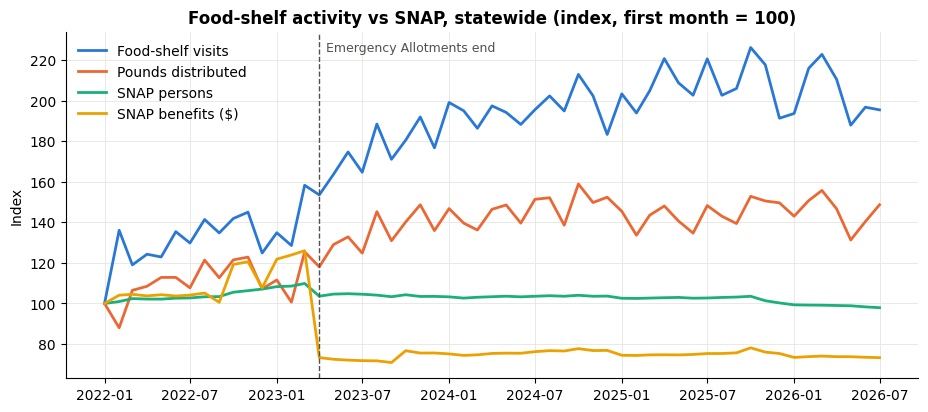

In [49]:
state = (panel.groupby("month")[["visits", "pounds", "individuals"]].sum()
         .join(snap.groupby("month")[["snap_persons", "snap_benefits"]].sum()))
base = state.iloc[0]
idx = state / base * 100

fig, ax = plt.subplots()
for col, color, label in [("visits", C1, "Food-shelf visits"), ("pounds", C2, "Pounds distributed"),
                          ("snap_persons", C3, "SNAP persons"), ("snap_benefits", C4, "SNAP benefits ($)")]:
    ax.plot(idx.index, idx[col], color=color, label=label)
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.annotate("Emergency Allotments end", (EA_FIRST_POST, ax.get_ylim()[1]), xytext=(5, -14),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title("Food-shelf activity vs SNAP, statewide (index, first month = 100)")
ax.set_ylabel("Index")
ax.legend(frameon=False, loc="upper left")
plt.show()

> **What this result means**
- **SNAP benefits** (yellow) drop by about **40% in April 2023** (index ≈125 → ≈73) and stay at that level. **SNAP persons** (green) are nearly flat, with a small decline in 2026.
- **Food-shelf visits** (blue) **roughly double**: index ≈100 in early 2022, ≈200 from 2024 on, peak ≈226 in Oct 2025. **Pounds** (orange) rise only about **+45–55%**, so **food per visit fell by roughly a quarter**: shelves serve more households with less food each.
- Visits were **already rising before EA ended** (≈130–158 in Jan–Mar 2023). The cut did not start the increase; at most it kept it going.
- With the §2.5 cleaning applied, there is no artificial July 2023 spike.

### 5.2 Lead/lag correlation of YoY changes (statewide)

> **Purpose:** Test whether changes in SNAP come *before* changes in food-shelf use, and by how many months. A negative correlation with benefit per person means less SNAP money is followed by more food-shelf use.

In [50]:
# all three metrics
st = state.copy()
st["benefit_pp"] = st["snap_benefits"] / st["snap_persons"]
yoy = np.log(st).diff(12)
rows = []
for k in range(0, 7):
    rows.append({"lag_months": k,
                 "corr(visits, benefit_pp)":        yoy["visits"].corr(yoy["benefit_pp"].shift(k)),
                 "corr(pounds, benefit_pp)":        yoy["pounds"].corr(yoy["benefit_pp"].shift(k)),
                 "corr(individuals, benefit_pp)":   yoy["individuals"].corr(yoy["benefit_pp"].shift(k)),
                 "corr(visits, snap_persons)":      yoy["visits"].corr(yoy["snap_persons"].shift(k)),
                 "corr(individuals, snap_persons)": yoy["individuals"].corr(yoy["snap_persons"].shift(k))})
pd.DataFrame(rows).round(2)

,lag_months,"corr(visits, benefit_pp)","corr(pounds, benefit_pp)","corr(individuals, benefit_pp)","corr(visits, snap_persons)","corr(individuals, snap_persons)"
0,0,-0.66,-0.56,-0.62,0.16,0.27
1,1,-0.71,-0.63,-0.68,0.11,0.24
2,2,-0.63,-0.64,-0.72,0.31,0.21
3,3,-0.61,-0.62,-0.70,0.36,0.26
4,4,-0.57,-0.62,-0.66,0.42,0.35
5,5,-0.52,-0.56,-0.56,0.49,0.47
6,6,-0.52,-0.57,-0.54,0.50,0.51


> **What this result means**
- **Visits vs benefit per person:** **−0.66 at lag 0, −0.71 at lag 1**, still −0.52 at lag 6. **Pounds:** −0.56 to −0.64 at every lag. Less SNAP money per person goes with more food-shelf use.
- **Visits vs SNAP persons:** positive (+0.11 → +0.50). Enrollment and food-shelf use rise together because both track need.
- **Read with care:** YoY benefit per person is ≈0 in every month except Apr 2023 – Mar 2024, when it is ≈−40%. These correlations therefore mostly say **"the year after EA ended was a year of fast food-shelf growth."** That is **one event**, so it is consistent with substitution but cannot rule out other 2023 shocks such as food prices (Q4). The lag pattern reflects the shape of that one step, not a precise response time.

### 5.3 Panel regression with county and month fixed effects

> **Purpose:** Ask the same question *within* each county. Is a county busier at its food shelves in months when its own SNAP enrollment or benefit per person is higher, after removing statewide shocks?

$$\ln Y_{ct} = \beta_1 \ln(\text{SNAP persons})_{ct} + \beta_2 \ln(\text{benefit per person})_{ct} + \alpha_c + \gamma_t + \varepsilon_{ct}$$

* $\alpha_c$ (unit fixed effects): compares each county **with itself**, so no population data is needed.
* $\gamma_t$ (month fixed effects): absorbs statewide shocks such as inflation, seasonality, and the statewide EA cut.
* Standard errors are clustered by SNAP unit.

**Interpretation:** $\beta_1 > 0$ means enrollment and food-shelf use **move together** (both track need). $\beta_2 < 0$ means more generous SNAP **replaces** food-shelf use. Both can hold at once.

In [51]:
def fe_reg(df, y, rhs="ln_snap_persons + ln_benefit_pp", extra=""):
    d = df.dropna(subset=[y, "ln_snap_persons", "ln_benefit_pp"])
    m = smf.ols(f"{y} ~ {rhs} {extra} + C(snap_unit) + C(month)", data=d).fit(
        cov_type="cluster", cov_kwds={"groups": pd.factorize(d["snap_unit"])[0]})
    return m

res = []
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    m = fe_reg(panel, y)
    for v in ["ln_snap_persons", "ln_benefit_pp"]:
        res.append({"outcome": y, "term": v, "coef": m.params[v], "se": m.bse[v],
                    "p": m.pvalues[v], "n": int(m.nobs)})
q5a = pd.DataFrame(res).round(3)
q5a

,outcome,term,coef,se,p,n
0,ln_visits,ln_snap_persons,0.160,0.106,0.133,4559
1,ln_visits,ln_benefit_pp,0.400,0.193,0.038,4559
2,ln_pounds,ln_snap_persons,-0.041,0.140,0.771,4558
3,ln_pounds,ln_benefit_pp,0.308,0.206,0.136,4558
4,ln_individuals,ln_snap_persons,0.126,0.113,0.267,4558
5,ln_individuals,ln_benefit_pp,0.253,0.193,0.190,4558


> **What this result means**
- **Enrollment (β₁):** +0.16 for visits (p = 0.13). The sign is positive but **not significant**.
- **Benefit per person (β₂):** +0.40 for visits (p = 0.04). This is the opposite sign from substitution, but it **disappears in the all-sites version** (−0.004, p = 0.99, see §8). It is not a real effect.
- **Why:** month fixed effects remove the statewide EA cut, the only large benefit change. What remains is small county differences in benefit per person, which mostly reflect household mix (children, seniors), not policy.
- **Takeaway:** within counties, month to month, there is **no reliable relationship**. Keep this as a robustness check; do not use it as the headline.

### 5.4 Add population: rates per 1,000 residents

> **Purpose:** Put SNAP and food-shelf activity on the same per-resident scale so counties of very different size can be compared. Consortia (MNPrairie, Pope + Grant) get the summed population of their member counties.

In [52]:
pop_mn = pop_mn_raw.copy()
pop_mn["county"] = pop_mn["COUNTY"].astype(int).map(lambda c: FIPS_TO_COUNTY.get(f"27{c:03d}"))
assert pop_mn["county"].notna().all() and len(pop_mn) == 87, "County FIPS did not map cleanly"
pop_mn["snap_unit"] = pop_mn["county"].map(COUNTY_TO_UNIT)

pop = (pop_mn.melt(id_vars="snap_unit", value_vars=[f"POPESTIMATE{y}" for y in range(2020, 2026)],
                   var_name="year", value_name="pop")
         .assign(year=lambda d: d["year"].str[-4:].astype(int))
         .groupby(["snap_unit", "year"], as_index=False)["pop"].sum())

def add_pop(p):
    p = p.drop(columns=[c for c in ["year", "pop"] if c in p.columns]).copy()
    p["year"] = p["month"].dt.year.clip(upper=2025)          # 2026 months use the 2025 estimate
    p = p.merge(pop, on=["snap_unit", "year"], how="left", validate="many_to_one")
    for c in ["visits", "pounds", "individuals", "snap_persons"]:
        p[f"{c}_per_1k"] = p[c] / p["pop"] * 1000
    return p

panel, panel_all = add_pop(panel), add_pop(panel_all)
print(f"Rows without population: {panel['pop'].isna().sum()} (balanced) / {panel_all['pop'].isna().sum()} (all sites)")
print(f"SNAP units with population: {pop['snap_unit'].nunique()}")
panel_all[["snap_persons_per_1k", "visits_per_1k", "pounds_per_1k"]].describe().round(1)

Rows without population: 0 (balanced) / 0 (all sites)
SNAP units with population: 84


,snap_persons_per_1k,visits_per_1k,pounds_per_1k
count,4561.0,4561.0,4561.0
mean,80.6,26.4,1574.6
std,52.2,18.2,1021.0
min,15.0,2.0,0.0
25%,58.4,15.1,963.7
50%,72.0,21.2,1328.2
75%,91.7,31.2,1891.7
max,538.2,147.9,15078.0


> **What this result means**
- **Every row has a population** (0 missing), and all 84 SNAP units are covered once the consortia are summed.
- Typical unit-month: **72 SNAP recipients per 1,000 residents** (median; middle half 58–92) and **21 food-shelf visits per 1,000 residents per month** (middle half 15–31).
- **Mahnomen** is the extreme case (≈538 SNAP recipients per 1,000) because White Earth Band's caseload is folded into it. This is why the later steps also report results without Mahnomen.

### 5.5 Across counties: do SNAP participation and food-shelf use go together?

> **Purpose:** Answer Q5-A across space. Do counties where a larger share of residents use SNAP also have more food-shelf visits per resident? A positive link means the two **track the same need** (complements); no link or a negative one would suggest they serve different people.

Units: 83 | Spearman rho (SNAP per 1k vs visits per 1k, 2024): 0.17
log visits/1k on log SNAP/1k: elasticity 0.30 (se 0.12, p=0.010)
log pounds/1k on log SNAP/1k: elasticity 0.22 (se 0.11, p=0.040)
log individuals/1k on log SNAP/1k: elasticity 0.30 (se 0.12, p=0.009)


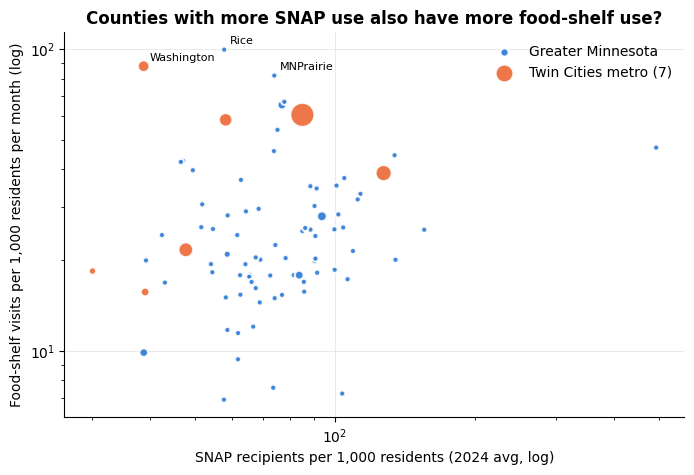

In [53]:
# all three metrics
xs = (panel_all[panel_all["month"].dt.year == 2024]
        .groupby("snap_unit")
        .agg(snap_per_1k=("snap_persons_per_1k", "mean"), visits_per_1k=("visits_per_1k", "mean"),
             pounds_per_1k=("pounds_per_1k", "mean"), individuals_per_1k=("individuals_per_1k", "mean"),
             n_sites=("n_sites", "mean"), pop=("pop", "mean"), metro=("metro", "first"))
        .replace([np.inf, -np.inf], np.nan).dropna())
xs = xs[(xs["visits_per_1k"] > 0) & (xs["snap_per_1k"] > 0)
        & (xs["pounds_per_1k"] > 0) & (xs["individuals_per_1k"] > 0)]

rho = xs[["snap_per_1k", "visits_per_1k"]].corr(method="spearman").iloc[0, 1]
xs_models = {}
print(f"Units: {len(xs)} | Spearman rho (SNAP per 1k vs visits per 1k, 2024): {rho:.2f}")
for name in ["visits", "pounds", "individuals"]:
    m = smf.ols(f"np.log({name}_per_1k) ~ np.log(snap_per_1k) + metro", data=xs).fit(cov_type="HC1")
    xs_models[name] = m
    print(f"log {name}/1k on log SNAP/1k: elasticity {m.params['np.log(snap_per_1k)']:.2f} "
          f"(se {m.bse['np.log(snap_per_1k)']:.2f}, p={m.pvalues['np.log(snap_per_1k)']:.3f})")
m_xs, m_xs_lb, m_xs_ind = xs_models["visits"], xs_models["pounds"], xs_models["individuals"]

fig, ax = plt.subplots(figsize=(8, 5))
for flag, color, label in [(0, C1, "Greater Minnesota"), (1, C2, "Twin Cities metro (7)")]:
    s = xs[xs["metro"] == flag]
    ax.scatter(s["snap_per_1k"], s["visits_per_1k"], s=np.clip(s["pop"] / 4000, 20, 300), color=color,
               label=label, edgecolor="white", linewidth=1.5, alpha=0.9, zorder=3)
for unit, r in xs.nlargest(3, "visits_per_1k").iterrows():
    ax.annotate(unit, (r["snap_per_1k"], r["visits_per_1k"]), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("SNAP recipients per 1,000 residents (2024 avg, log)")
ax.set_ylabel("Food-shelf visits per 1,000 residents per month (log)")
ax.set_title("Counties with more SNAP use also have more food-shelf use?")
ax.legend(frameon=False)
plt.show()

> **What this result means**
- Across 83 units in 2024, a **1% higher SNAP participation rate goes with a 0.30% higher food-shelf visit rate** (p = 0.010) and a **0.22% higher pounds rate** (p = 0.040), holding metro status fixed.
- **Meaning:** places where more residents need SNAP also need food shelves more. **The two move together across counties.** They respond to the same underlying need, so one does not replace the other.
- The rank correlation is weak (ρ = 0.17) and the cloud is wide. SNAP use explains only part of the county differences.
- The highest visit rates (**Rice, Washington, MNPrairie**) probably reflect where The Food Group's partner network is dense, not where need is highest. Present the **slope**, not the ranking of counties.

## 6. Q5-B — What happens to food shelves when SNAP benefits change?

### 6.1 The benefit change: end of Emergency Allotments

> **Purpose:** Confirm when the EA cut appears in the SNAP data and how large it was in each county (the "dose").

Every SNAP household got EA through the Feb 2023 issuance; then it stopped. Because the dashboard uses **accounting months**, the Feb 2023 EA payment shows up in **March**, so the drop appears in **April 2023** (printed below). The cut was statewide, but the **size of the cut per person differed by county**. That difference is our "dose":

$$\text{dose}_c = \overline{\text{benefit\_pp}}_{c,\,\text{Jan–Mar 2023}} - \overline{\text{benefit\_pp}}_{c,\,\text{Apr–Jun 2023}}$$

**Design (dose-response difference-in-differences on YoY changes):**
* **Pre:** Jan–Mar 2023 vs Jan–Mar 2022. Both years had EA, so this works as a placebo.
* **Post:** Apr–Sep 2023 vs Apr–Sep 2022. EA was present in 2022 and absent in 2023.
* Outcome = post YoY change − pre YoY change, regressed on dose (in $10 per person).

If the coefficient is **positive**, counties that lost more SNAP money saw food-shelf use rise more, which is evidence of **substitution**.

In [54]:
ppm = snap.set_index(["snap_unit", "month"])["benefit_pp"].unstack()
print("Statewide benefit per person around the EA end:")
print((snap.groupby("month")[["snap_benefits", "snap_persons"]].sum()
       .assign(benefit_pp=lambda d: d.snap_benefits / d.snap_persons)
       .loc["2022-11":"2023-06", "benefit_pp"].round(1)).to_string())

dose = (ppm.loc[:, "2023-01":"2023-03"].mean(axis=1) - ppm.loc[:, "2023-04":"2023-06"].mean(axis=1)).rename("dose")
print("\nEA cut per SNAP person ($/month) across units:")
print(dose.describe().round(1).to_string())
# Note: if the spread is small, the cross-county test has limited power. Say so on the slide.

Statewide benefit per person around the EA end:
month
2022-11-01    256.9
2022-12-01    227.9
2023-01-01    254.9
2023-02-01    258.6
2023-03-01    259.9
2023-04-01    160.3
2023-05-01    157.0
2023-06-01    155.8

EA cut per SNAP person ($/month) across units:
count     84.0
mean     110.5
std        9.3
min       84.6
25%      105.3
50%      112.9
75%      116.9
max      126.1


> **What this result means**
- Statewide benefit per person was **$260 in March 2023 and $160 in April 2023 (−38%)**. This confirms April 2023 as the first month without EA in accounting months. The December 2022 dip ($228) is a payment-timing artefact.
- The cut averaged **$110 per SNAP person per month**. Across units it ranges only from **$85 to $126 (sd $9)**, so almost every county lost about the same amount per person. With so little variation, the cross-county comparison in §6.2 has little power.

### 6.1b How much SNAP money left Minnesota households?

> **Purpose:** Put the EA cut in dollars. Compare statewide food benefits in the last three months with EA (Jan–Mar 2023) and the first three months without it (Apr–Jun 2023). This is the number lawmakers will ask for.

In [55]:
# Statewide food benefits before vs after the EA end (source of the "$49 million per month" figure in Section 9)
state_ben = snap.groupby("month")["snap_benefits"].sum()
pre_ea  = state_ben.loc["2023-01-01":"2023-03-01"].mean()
post_ea = state_ben.loc["2023-04-01":"2023-06-01"].mean()
print(f"Statewide SNAP+MFAP+MFIP food benefits, monthly avg: "
      f"Jan–Mar 2023 ${pre_ea/1e6:,.1f}M → Apr–Jun 2023 ${post_ea/1e6:,.1f}M "
      f"(loss ${(pre_ea - post_ea)/1e6:,.1f}M per month)")

Statewide SNAP+MFAP+MFIP food benefits, monthly avg: Jan–Mar 2023 $119.4M → Apr–Jun 2023 $69.9M (loss $49.4M per month)


> **What this result means**
- Statewide food benefits (federal SNAP + state MFAP/MFIP food portions) averaged **$119.4M per month in Jan–Mar 2023** and **$69.9M in Apr–Jun 2023**. Ending Emergency Allotments removed about **$49.4M per month (−41%)** from Minnesota households' food budgets.
- This is the source of the "$49 million per month" figure in Section 9.

### 6.2 Dose-response difference-in-differences

> **Purpose:** Test whether counties that lost more SNAP money per person saw a bigger rise in food-shelf use after April 2023, using the change in YoY growth from before to after the cut.

In [56]:
def window_mean(p, col, start, end):
    w = p[(p["month"] >= start) & (p["month"] <= end)]
    return w.groupby("snap_unit")[col].mean()

def ea_did(p, metric):
    pre  = np.log(window_mean(p, metric, "2023-01-01", "2023-03-01")) - np.log(window_mean(p, metric, "2022-01-01", "2022-03-01"))
    post = np.log(window_mean(p, metric, "2023-04-01", "2023-09-01")) - np.log(window_mean(p, metric, "2022-04-01", "2022-09-01"))
    out = pd.DataFrame({"pre_yoy": pre, "post_yoy": post}).join(dose)
    out["did"] = out["post_yoy"] - out["pre_yoy"]
    out["dose10"] = out["dose"] / 10
    out["metro"] = out.index.isin(METRO7).astype(int)
    out["weight"] = window_mean(p, metric, "2022-01-01", "2022-03-01")   # size of the unit before the cut
    return out.replace([np.inf, -np.inf], np.nan).dropna()

ea_rows, ea_data = [], {}
for metric in ["visits", "pounds", "individuals"]:
    d = ea_did(panel, metric)
    ea_data[metric] = d
    m = smf.ols("did ~ dose10", data=d).fit(cov_type="HC1")
    ea_rows.append({"metric": metric, "units": len(d),
                    "mean post-pre": d["did"].mean(),
                    "median post-pre": d["did"].median(),
                    "size-weighted post-pre": np.average(d["did"], weights=d["weight"]),
                    "dose coef (per $10/person)": m.params["dose10"],
                    "se": m.bse["dose10"], "p": m.pvalues["dose10"]})
q5b = pd.DataFrame(ea_rows).round(3)
q5b

,metric,units,mean post-pre,median post-pre,size-weighted post-pre,dose coef (per $10/person),se,p
0,visits,83,0.108,0.051,0.100,0.021,0.028,0.451
1,pounds,83,-0.051,0.014,0.023,0.003,0.023,0.897
2,individuals,83,0.012,0.017,-0.052,0.043,0.028,0.127


> **What this result means**
- After the cut, YoY visit growth was **about +10% higher** than before it (size-weighted +0.100; median +0.051). **Pounds (+0.02) and individuals (−0.05) barely changed**: more households came, but the amount of food going out did not keep pace.
- **Dose coefficient = +0.02 (p = 0.45):** counties that lost more SNAP money per person did **not** see bigger increases.
- This does **not** mean SNAP doesn't matter. The cut was almost identical everywhere (sd $9 per person, §6.1), so the test has nothing to compare. **Per-person** dose is the wrong exposure measure; §6.6 repeats the test with SNAP dollars lost **per resident**.

### 6.3 Event-study view by dose group

> **Purpose:** Look month by month at whether visit growth jumped in April 2023, and whether high-cut and low-cut counties split apart afterwards.

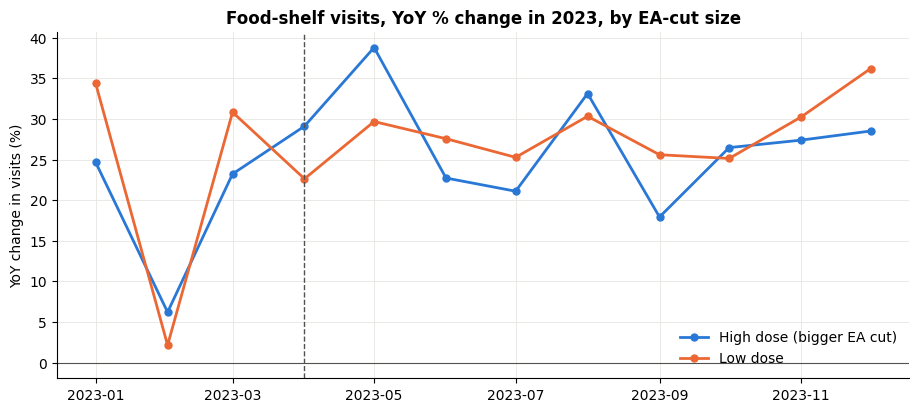

In [57]:
grp = (dose > dose.median()).map({True: "High dose (bigger EA cut)", False: "Low dose"})
es = panel.assign(group=panel["snap_unit"].map(grp)).dropna(subset=["yoy_visits", "group"])
es = es[(es["month"] >= "2023-01-01") & (es["month"] <= "2023-12-01")]
es_m = es.groupby(["month", "group"]).apply(
    lambda g: np.average(g["yoy_visits"], weights=g["visits"]), include_groups=False).unstack()

fig, ax = plt.subplots()
for col, color in zip(es_m.columns, [C1, C2]):
    ax.plot(es_m.index, es_m[col] * 100, marker="o", ms=5, color=color, label=col)
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_title("Food-shelf visits, YoY % change in 2023, by EA-cut size")
ax.set_ylabel("YoY change in visits (%)"); ax.legend(frameon=False)
plt.show()

> **What this result means**
- Both groups grow **+20–40% YoY all through 2023, including Jan–Mar, before the cut**. The lines **do not separate after April**.
- There is no visible jump at April 2023 in either group. The 2023 surge was already underway, matching the statewide chart in §5.1.

### 6.4 Second benefit change: the 2026 enrollment drop

> **Purpose:** Use the 2026 SNAP enrollment decline as a second, independent episode. Did counties that lost more SNAP enrollees see food-shelf visits rise more?

In [58]:
# all three metrics
if panel["month"].max() >= pd.Timestamp("2026-03-01"):
    last = panel["month"].max()
    w26 = panel[(panel["month"] >= "2026-01-01") & (panel["month"] <= last)]
    d26 = (w26.groupby("snap_unit")[["yoy_visits", "yoy_pounds", "yoy_individuals", "yoy_snap_persons"]]
              .mean().dropna())
    d26["metro"] = d26.index.isin(METRO7).astype(int)
    for y in ["yoy_visits", "yoy_pounds", "yoy_individuals"]:
        m = smf.ols(f"{y} ~ yoy_snap_persons", data=d26).fit(cov_type="HC1")
        print(f"{y:16s} on YoY SNAP persons: coef={m.params['yoy_snap_persons']:.3f} "
              f"(se {m.bse['yoy_snap_persons']:.3f}, p={m.pvalues['yoy_snap_persons']:.3f}), n={len(d26)}")
else:
    print(f"Food-shelf data ends {panel['month'].max():%Y-%m}; 2026 analysis skipped.")

yoy_visits       on YoY SNAP persons: coef=-0.212 (se 0.284, p=0.455), n=82
yoy_pounds       on YoY SNAP persons: coef=-0.115 (se 0.474, p=0.808), n=82
yoy_individuals  on YoY SNAP persons: coef=-0.177 (se 0.304, p=0.560), n=82


> **What this result means**
- Coefficient for visits = **−0.21 (p = 0.46)**. Counties that lost more SNAP enrollees had slightly *higher* visit growth (the substitution direction), but the estimate is **not significant**.
- Only Jan–Jul 2026 is available. This is the most policy-relevant episode (TFG: 16,000 Minnesotans lost benefits in 2026), so re-run it when more months arrive.

### 6.5 Did the EA cut matter after controlling for food prices? (interrupted time series)

> **Purpose:** Answer the judges' most likely objection to Q5-B: *"Wasn't the 2023 surge just food inflation?"* The statewide model separates three things: the steady trend, the level of food prices (CPI), and a shift starting April 2023 when EA ended. Month-of-year dummies remove seasonality, and Newey-West standard errors allow for correlation between neighbouring months.

In [59]:
ts = (panel.groupby("month")[["visits", "pounds", "individuals"]].sum()
        .join(snap.groupby("month")[["snap_persons", "snap_benefits"]].sum())
        .join(cpi.set_index("month")["cpi_food_home"])
        .dropna())
ts["benefit_pp"] = ts["snap_benefits"] / ts["snap_persons"]
ts["t"] = np.arange(len(ts))
ts["post_ea"] = (ts.index >= EA_FIRST_POST).astype(int)
ts["moy"] = ts.index.month
for c in ["visits", "pounds", "individuals", "cpi_food_home", "benefit_pp"]:
    ts[f"ln_{c}"] = np.log(ts[c])

its_rows, its_models = [], {}
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    # A: did the level shift when EA ended, holding food prices and trend fixed?
    mA = smf.ols(f"{y} ~ t + post_ea + ln_cpi_food_home + C(moy)", data=ts).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    # B: same idea with the continuous SNAP benefit per person instead of a before/after dummy
    mB = smf.ols(f"{y} ~ t + ln_benefit_pp + ln_cpi_food_home + C(moy)", data=ts).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    its_models[y] = mA
    its_rows.append({"outcome": y,
                     "A: post-EA shift": mA.params["post_ea"], "A: p": mA.pvalues["post_ea"],
                     "A: % change": (np.exp(mA.params["post_ea"]) - 1) * 100,
                     "A: CPI elasticity": mA.params["ln_cpi_food_home"], "A: CPI p": mA.pvalues["ln_cpi_food_home"],
                     "B: benefit_pp elasticity": mB.params["ln_benefit_pp"], "B: p": mB.pvalues["ln_benefit_pp"],
                     "n months": int(mA.nobs)})
q5b_its = pd.DataFrame(its_rows).round(3)
print(f"Correlation of trend with log CPI over this window: {ts['t'].corr(ts['ln_cpi_food_home']):.2f}")
q5b_its

Correlation of trend with log CPI over this window: 0.89


,outcome,A: post-EA shift,A: p,A: % change,A: CPI elasticity,A: CPI p,B: benefit_pp elasticity,B: p,n months
0,ln_visits,0.229,0.0,25.711,1.007,0.055,-0.502,0.0,54
1,ln_pounds,0.161,0.0,17.501,0.806,0.135,-0.352,0.0,54
2,ln_individuals,0.262,0.0,30.014,2.688,0.001,-0.582,0.0,54


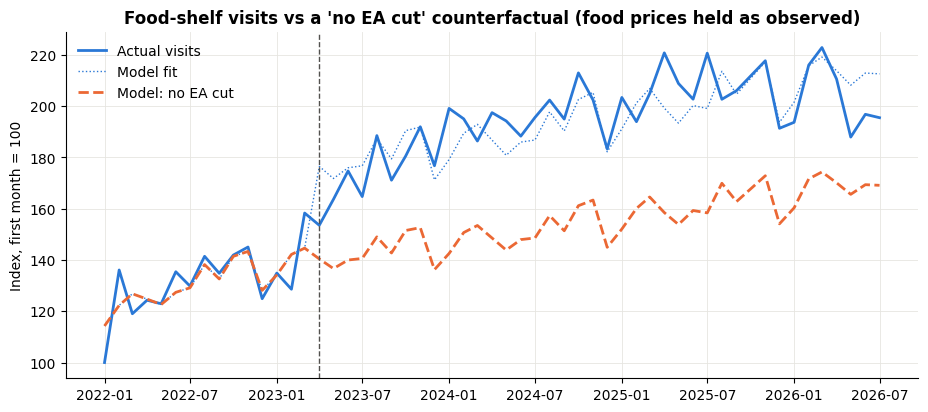

In [60]:
# Chart: actual visits vs the model's "no EA cut" counterfactual (same trend, prices, seasonality)
mA = its_models["ln_visits"]
cf = ts.assign(post_ea=0)
ts["fit"] = np.exp(mA.predict(ts))
ts["counterfactual"] = np.exp(mA.predict(cf))
base = ts["visits"].iloc[0]

fig, ax = plt.subplots()
ax.plot(ts.index, ts["visits"] / base * 100, color=C1, label="Actual visits")
ax.plot(ts.index, ts["fit"] / base * 100, color=C1, lw=1, ls=":", label="Model fit")
ax.plot(ts.index, ts["counterfactual"] / base * 100, color=C2, lw=2, ls="--", label="Model: no EA cut")
ax.axvline(EA_FIRST_POST, color="#52514e", ls="--", lw=1)
ax.set_title("Food-shelf visits vs a 'no EA cut' counterfactual (food prices held as observed)")
ax.set_ylabel("Index, first month = 100"); ax.legend(frameon=False, loc="upper left")
plt.show()

> **What this result means**
- **After April 2023, visits ran about 26% above** what the trend, food prices and seasonality predict (shift +0.229, p < 0.001). **Individuals +30%** (p < 0.001) and **pounds +18%** (p < 0.001).
- **Food prices matter too.** The CPI elasticity is ≈1.0 for visits (p = 0.055) and 2.7 for individuals (p = 0.001), consistent with Q4. But **the EA shift stays large even with prices in the model**, so the 2023 surge was **not just inflation**.
- **Spec B:** benefit-per-person elasticity **−0.50** for visits (p < 0.001). A 10% lower SNAP benefit per person goes with about **5% more visits**. This is direct evidence of **substitution** over time.
- **Chart:** the orange "no EA cut" line keeps rising (trend and prices), but actual visits jump above it in spring 2023. The chart assumes the shift is permanent; the segmented model in §6.5c finds the jump is robust but cannot tell whether it persisted or faded.
- **Limits:** trend and CPI are highly correlated (0.89), there is only one break, and other pandemic-era supports also wound down in 2023. The placebo check below tests whether April 2023 actually stands out.

### 6.5b Placebo check: is April 2023 special?

> **Purpose:** A before/after dummy can look significant at **any** date if the trend simply bends. Re-estimate Spec A with a fake break at every month from mid-2022 to mid-2025. If April 2023 gives one of the largest shifts, the EA timing is credible; if many dates give similar shifts, the +26% partly reflects the shape of the trend and should be stated more cautiously.

April 2023 ranks #4 of 36 candidate break months by model fit (R²).
Top 5 break months by fit:
            shift  t_stat     r2
break                           
2023-05-01  0.243   7.336  0.927
2023-06-01  0.239   6.704  0.921
2023-03-01  0.232   7.005  0.916
2023-04-01  0.229   6.427  0.915
2023-08-01  0.238   6.046  0.908


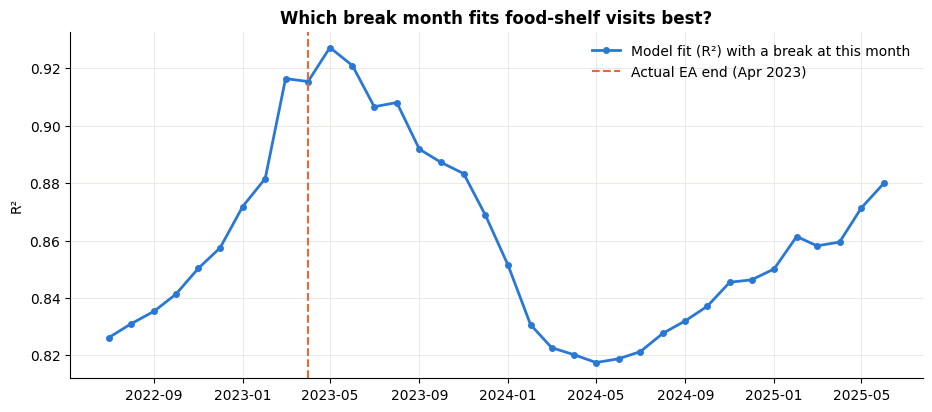

In [61]:

breaks = pd.date_range("2022-07-01", "2025-06-01", freq="MS")
rows = []
for b in breaks:
    tsb = ts.assign(post_b=(ts.index >= b).astype(int))
    mb = smf.ols("ln_visits ~ t + post_b + ln_cpi_food_home + C(moy)", data=tsb).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    rows.append({"break": b, "shift": mb.params["post_b"], "t_stat": mb.tvalues["post_b"], "r2": mb.rsquared})
plc = pd.DataFrame(rows).set_index("break")
rank = plc["r2"].rank(ascending=False)[EA_FIRST_POST]
print(f"April 2023 ranks #{int(rank)} of {len(plc)} candidate break months by model fit (R²).")
print("Top 5 break months by fit:"); print(plc.sort_values("r2", ascending=False).head(5).round(3).to_string())

fig, ax = plt.subplots()
ax.plot(plc.index, plc["r2"], color=C1, marker="o", ms=4, label="Model fit (R²) with a break at this month")
ax.axvline(EA_FIRST_POST, color=C2, ls="--", lw=1.5, label="Actual EA end (Apr 2023)")
ax.set_title("Which break month fits food-shelf visits best?")
ax.set_ylabel("R²")
ax.legend(frameon=False, loc="upper right")
plt.show()

> **What this result means**
- **The data pick spring 2023 as the turning point.** The four best-fitting break months are **May, June, March and April 2023** (R² 0.915–0.927), all within two months of the EA end. April itself ranks #4, only 0.012 below the best.
- **Breaks outside that window fit clearly worse.** Fit falls to ≈0.83–0.85 for breaks in late 2022 and in 2024–25. The small rise at the far right is an edge effect: with few months left after the break, the dummy starts fitting individual months.
- **Why not exactly April:** accounting-month timing (some EA-era payments land in March) and households taking a month or two to run through savings and pantry stocks blur the exact month. The data cannot separate March from June 2023, but they **do** say the step-up happened in the EA-end window and nowhere else.
- **Conclusion for Q5-B:** the +26% shift in §6.5 is not an artefact of where we placed the break. It is the strongest single change in the series, and it lines up with the end of Emergency Allotments.

### 6.5c Does the post-EA shift persist or fade? (segmented regression)

> **Purpose:** Spec A assumes the April 2023 shift is permanent, and the counterfactual chart inherits that assumption. Adding a separate post-cut slope tests whether the step held or faded, and gives a more conservative estimate of its size.

In [62]:
# t_since = months since EA ended (0 before).
# Coef ≈ 0 → the shift persists; < 0 → it fades over time.
ts["t_since"] = (ts["t"] - ts.loc[EA_FIRST_POST, "t"]).clip(lower=0)
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    m = smf.ols(f"{y} ~ t + post_ea + t_since + ln_cpi_food_home + C(moy)", data=ts).fit(
        cov_type="HAC", cov_kwds={"maxlags": 3})
    print(f"{y:15s} shift {m.params['post_ea']:+.3f} (p={m.pvalues['post_ea']:.3f}) | "
          f"post slope {m.params['t_since']:+.4f}/month (p={m.pvalues['t_since']:.3f})")

ln_visits       shift +0.162 (p=0.009) | post slope -0.0130/month (p=0.164)
ln_pounds       shift +0.132 (p=0.012) | post slope -0.0056/month (p=0.543)
ln_individuals  shift +0.230 (p=0.003) | post slope -0.0063/month (p=0.595)


> **What this result means**
- Spec A assumes the post-EA shift is permanent. Here the trend is allowed to change after April 2023 (`t_since`) to test that assumption.
- **The shift survives:** visits **+18%** (+0.162, p = 0.009), pounds **+14%** (p = 0.012), individuals **+26%** (p = 0.003). The EA effect does not depend on assuming it lasts forever.
- **Persistence cannot be determined:** the post-EA slope is negative for all three metrics but not significant (visits −0.013/month, p = 0.16). The data neither confirm that the gap stayed open nor that it closed.
- **Reporting:** use a range, **+18% to +26% for visits**, depending on whether the post-cut trend is allowed to differ. The lower end is close to Q4's estimate of the EA shock (+16–19, different model).

### 6.6 Dose-response with SNAP dollars lost **per resident**

> **Purpose:** Redo the §6.2 county test with an exposure measure that actually varies. Every SNAP recipient lost about the same amount (≈$110), but counties differ a lot in **how many** residents use SNAP. Total EA dollars lost **per resident** measures how big the shock was for the local community, and therefore for its food shelves.

In [63]:
snap_pop = snap.assign(year=snap["month"].dt.year).merge(pop, on=["snap_unit", "year"], how="inner")
def mean_window(df, col, a, b):
    return df[(df["month"] >= a) & (df["month"] <= b)].groupby("snap_unit")[col].mean()
lost = mean_window(snap_pop, "snap_benefits", "2023-01-01", "2023-03-01") - mean_window(snap_pop, "snap_benefits", "2023-04-01", "2023-06-01")
pop23 = pop[pop["year"] == 2023].set_index("snap_unit")["pop"]
dose_res = (lost / pop23).rename("dose_res").dropna()       # $ lost per resident per month

print("EA $ lost per RESIDENT per month:")
print(dose_res.describe().round(2).to_string())
print(f"Spread (coefficient of variation): per resident {dose_res.std() / dose_res.mean():.2f} "
      f"vs per SNAP person {dose.std() / dose.mean():.2f}")

res_rows, res_data = [], {}
for metric in ["visits", "pounds", "individuals"]:
    d = ea_data[metric].join(dose_res, how="inner")
    d["dose_res5"] = d["dose_res"] / 5
    res_data[metric] = d
    for label, dd in [("all units", d), ("excl. Mahnomen", d.drop(index="Mahnomen", errors="ignore"))]:
        m = smf.wls("did ~ dose_res5", data=dd, weights=dd["weight"]).fit(cov_type="HC1")
        res_rows.append({"metric": metric, "sample": label, "units": len(dd),
                         "coef per $5/resident": m.params["dose_res5"], "se": m.bse["dose_res5"], "p": m.pvalues["dose_res5"]})
q5b_res = pd.DataFrame(res_rows).round(3)
q5b_res

EA $ lost per RESIDENT per month:
count    84.00
mean     10.12
std       5.19
min       3.01
25%       7.71
50%       9.16
75%      11.97
max      48.74
Spread (coefficient of variation): per resident 0.51 vs per SNAP person 0.08


,metric,sample,units,coef per $5/resident,se,p
0,visits,all units,83,0.030,0.081,0.711
1,visits,excl. Mahnomen,82,0.033,0.084,0.695
2,pounds,all units,83,-0.027,0.033,0.410
3,pounds,excl. Mahnomen,82,-0.027,0.036,0.443
4,individuals,all units,83,0.050,0.051,0.329
5,individuals,excl. Mahnomen,82,0.053,0.054,0.321


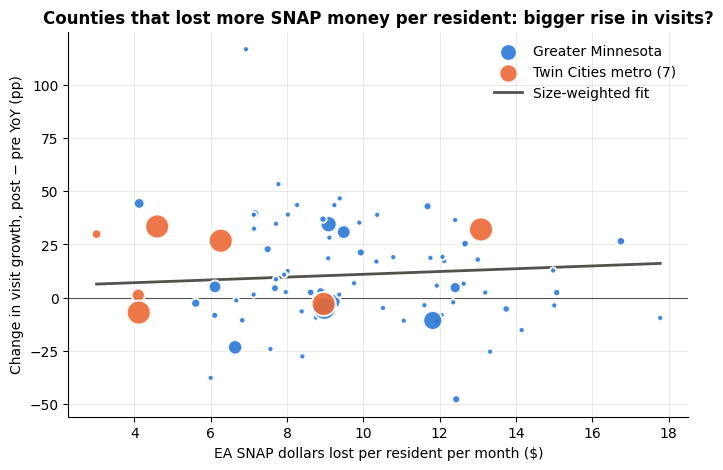

In [64]:
d = res_data["visits"].drop(index="Mahnomen", errors="ignore")
fig, ax = plt.subplots(figsize=(8, 5))
for flag, color, label in [(0, C1, "Greater Minnesota"), (1, C2, "Twin Cities metro (7)")]:
    s = d[d["metro"] == flag]
    ax.scatter(s["dose_res"], s["did"] * 100, s=np.clip(s["weight"] / 20, 20, 300), color=color, label=label,
               edgecolor="white", linewidth=1.5, alpha=0.9, zorder=3)
b = np.polyfit(d["dose_res"], d["did"] * 100, 1, w=np.sqrt(d["weight"]))
xs_ = np.linspace(d["dose_res"].min(), d["dose_res"].max(), 50)
ax.plot(xs_, np.polyval(b, xs_), color="#52514e", lw=2, label="Size-weighted fit")
ax.axhline(0, color="#52514e", lw=0.8)
ax.set_xlabel("EA SNAP dollars lost per resident per month ($)")
ax.set_ylabel("Change in visit growth, post − pre YoY (pp)")
ax.set_title("Counties that lost more SNAP money per resident: bigger rise in visits?")
ax.legend(frameon=False)
plt.show()

> **What this result means**
- The per-resident dose varies a lot: **$3 (Carver) to $18 (Traverse) per resident per month**, median $9. The printed maximum ($48.74) is Mahnomen, inflated because the whole White Earth Band caseload is folded into it (§5.4). That is about 6× more spread than the per-SNAP-person dose.
- Even so, **the coefficient is ≈0**: +0.03 per $5 for visits (p = 0.71), with similar non-results for pounds and individuals, with or without Mahnomen.
- **Meaning:** the post-April 2023 increase was **statewide and about the same size** whether a county lost $4 or $15 per resident. The EA evidence comes from **timing** (§6.5), not from geography.
- Likely reasons: households use shelves outside their home county, our data covers only The Food Group's partner network, and county-level changes are noisy (−50 to +117 pp). Say this on the limitations slide.

## 7. Q5-C — Does the relationship differ across locations?

### 7.1 Metro vs Greater Minnesota

> **Purpose:** Test whether the SNAP–food-shelf relationship is different in the 7-county Twin Cities metro than in the rest of the state.

In [65]:
res_c = []
for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
    # metro main effect is absorbed by the unit fixed effects, so only the interactions are added
    m = fe_reg(panel, y, rhs="ln_snap_persons + ln_benefit_pp + ln_snap_persons:metro + ln_benefit_pp:metro")
    for v in ["ln_benefit_pp", "ln_benefit_pp:metro", "ln_snap_persons", "ln_snap_persons:metro"]:
        res_c.append({"outcome": y, "term": v, "coef": m.params.get(v, np.nan),
                      "se": m.bse.get(v, np.nan), "p": m.pvalues.get(v, np.nan)})
pd.DataFrame(res_c).round(3)

,outcome,term,coef,se,p
0,ln_visits,ln_benefit_pp,0.411,0.195,0.035
1,ln_visits,ln_benefit_pp:metro,0.057,0.145,0.694
2,ln_visits,ln_snap_persons,0.155,0.108,0.151
3,ln_visits,ln_snap_persons:metro,0.310,0.562,0.582
4,ln_pounds,ln_benefit_pp,0.238,0.205,0.244
5,ln_pounds,ln_benefit_pp:metro,-0.126,0.153,0.410
6,ln_pounds,ln_snap_persons,-0.074,0.125,0.553
7,ln_pounds,ln_snap_persons:metro,1.026,0.944,0.277
8,ln_individuals,ln_benefit_pp,0.214,0.197,0.276
9,ln_individuals,ln_benefit_pp:metro,-0.039,0.118,0.741


> **What this result means**
- All `:metro` interaction terms are **not significant** (p = 0.15–0.74). There is **no measurable metro vs Greater MN difference**.
- Only 7 units are metro, so the test can only detect large gaps. Report this as "no evidence of a difference," not "proven the same."

### 7.2 County-by-county response to the EA cut

> **Purpose:** Show each unit's response so outliers and regional patterns are visible, and so the slide can name the counties that responded most.

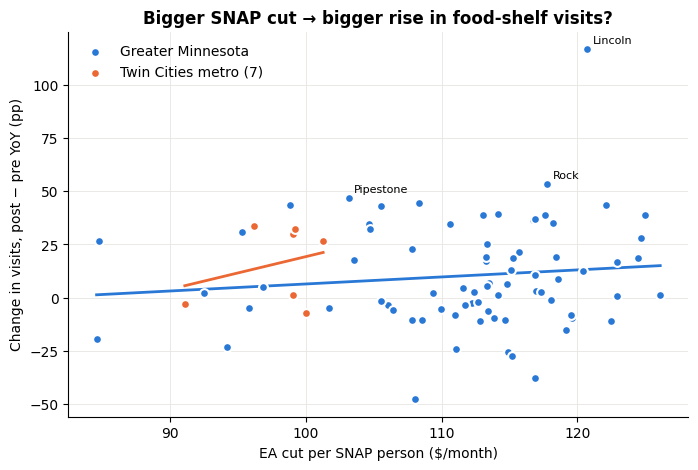

,dose,pre_yoy,post_yoy,did,metro
snap_unit,,,,,
Lincoln,120.750,-1.453,-0.286,1.168,0
Rock,117.770,-0.299,0.234,0.533,0
Pipestone,103.137,0.127,0.594,0.466,0
Wright,108.359,-0.074,0.369,0.443,0
Nobles,98.814,-0.195,0.241,0.435,0
Roseau,122.120,0.111,0.546,0.435,0
Kandiyohi,105.493,-0.192,0.238,0.429,0
McLeod,114.155,-0.933,-0.539,0.394,0
Brown,117.617,-0.179,0.211,0.390,0


In [66]:
d = ea_data["visits"]
fig, ax = plt.subplots(figsize=(8, 5))
for flag, color, label in [(0, C1, "Greater Minnesota"), (1, C2, "Twin Cities metro (7)")]:
    s = d[d["metro"] == flag]
    ax.scatter(s["dose"], s["did"] * 100, s=40, color=color, label=label,
               edgecolor="white", linewidth=1.5, zorder=3)
    if len(s) > 2:
        b = np.polyfit(s["dose"], s["did"] * 100, 1)
        xs = np.linspace(s["dose"].min(), s["dose"].max(), 50)
        ax.plot(xs, np.polyval(b, xs), color=color, lw=2)
for unit, r in d.nlargest(3, "did").iterrows():
    ax.annotate(unit, (r["dose"], r["did"] * 100), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set_xlabel("EA cut per SNAP person ($/month)")
ax.set_ylabel("Change in visits, post − pre YoY (pp)")
ax.set_title("Bigger SNAP cut → bigger rise in food-shelf visits?")
ax.legend(frameon=False)
plt.show()

d.sort_values("did", ascending=False)[["dose", "pre_yoy", "post_yoy", "did", "metro"]].round(3).head(10)

> **What this result means**
- Both fitted lines are nearly **flat**. The size of the per-person cut does not predict the change in visits, in the metro or in Greater MN.
- The labelled units (**Lincoln +117 pp, Rock +53, Pipestone +47**) are small rural counties with few sites. Lincoln's pre-period value (−1.45) shows a site missing in early 2023, so these are **noise, not findings**. Do not name them on a slide.

### 7.3 Does the EA response differ by county size (urban vs rural)?

> **Purpose:** Give Q5-C a fuller answer than metro vs non-metro. Counties are grouped by population (large ≥ 100k, mid 20k–100k, small < 20k, a simple urban–rural proxy). For each group we compare how much SNAP money residents lost and how food-shelf visits responded.

In [67]:
d = res_data["visits"].drop(index="Mahnomen", errors="ignore").join(pop23.rename("pop23"))
d["size"] = pd.cut(d["pop23"], [0, 20_000, 100_000, np.inf], labels=["Small (<20k)", "Mid (20k–100k)", "Large (≥100k)"])

grp = d.groupby("size", observed=True).apply(lambda g: pd.Series({
    "units": len(g),
    "median $ lost / resident": g["dose_res"].median(),
    "weighted change in visit growth (pp)": np.average(g["did"], weights=g["weight"]) * 100,
}), include_groups=False).round(2)
print(grp.to_string(), "\n")

m_size = smf.wls("did ~ dose_res5 * C(size)", data=d, weights=d["weight"]).fit(cov_type="HC1")
print("Dose slope by size group (per $5 lost per resident):")
for g in d["size"].cat.categories:
    term = "dose_res5" if g == d["size"].cat.categories[0] else f"dose_res5:C(size)[T.{g}]"
    what = "slope (baseline)" if term == "dose_res5" else "difference vs small"
    print(f"  {g:16s} {what:20s}: {m_size.params.get(term, np.nan):.3f} (p={m_size.pvalues.get(term, np.nan):.3f})")

                units  median $ lost / resident  weighted change in visit growth (pp)
size                                                                                 
Small (<20k)     35.0                      9.90                                 16.54
Mid (20k–100k)   35.0                      8.93                                  7.27
Large (≥100k)    12.0                      6.19                                 10.28 

Dose slope by size group (per $5 lost per resident):
  Small (<20k)     slope (baseline)    : -0.200 (p=0.302)
  Mid (20k–100k)   difference vs small : 0.246 (p=0.237)
  Large (≥100k)    difference vs small : 0.242 (p=0.274)


> **What this result means**
- **Small counties (<20k) lost the most per resident** (median $9.90 vs $8.93 mid and $6.19 large) and saw the **largest rise in visit growth** (+16.5 pp, vs +7.3 mid and +10.3 large).
- **But** the dose slopes do not differ significantly between groups (p = 0.24–0.30), and the small-county slope itself is not significant (p = 0.30). The pattern is **descriptive, not statistically confirmed**.
- **Q5-C answer:** the *relationship* looks similar across Minnesota. What differs is **how hard each place was hit**: rural, high-SNAP counties lost more SNAP dollars per resident and show the biggest increases in food-shelf use.

## 8. Robustness checks

### 8.1 Balanced panel vs all sites

> **Purpose:** Check that the Q5-A conclusion does not depend on which sites are included.

In [68]:
# all three metrics
checks = {"balanced panel (default)": panel, "all sites": panel_all}
rows = []
for name, p in checks.items():
    for y in ["ln_visits", "ln_pounds", "ln_individuals"]:
        m = fe_reg(p, y)
        rows.append({"version": name, "outcome": y,
                     "beta_persons": m.params["ln_snap_persons"], "beta_benefit_pp": m.params["ln_benefit_pp"],
                     "p_benefit_pp": m.pvalues["ln_benefit_pp"], "n": int(m.nobs)})
pd.DataFrame(rows).round(3)
# Also try: ERROR_POLICY="null_both", TRIBE_POLICY="drop", MIN_REPORT_SHARE=0.8 (edit Analysis Settings and re-run all)

,version,outcome,beta_persons,beta_benefit_pp,p_benefit_pp,n
0,balanced panel (default),ln_visits,0.160,0.400,0.038,4559
1,balanced panel (default),ln_pounds,-0.041,0.308,0.136,4558
2,balanced panel (default),ln_individuals,0.126,0.253,0.190,4558
3,all sites,ln_visits,0.239,-0.004,0.987,4561
4,all sites,ln_pounds,0.004,-0.010,0.965,4560
5,all sites,ln_individuals,0.199,-0.119,0.614,4560


> **What this result means**
- Benefit per person for visits: **+0.40 (p = 0.04, balanced) vs −0.004 (p = 0.99, all sites)**. The within-county β₂ is **not robust**.
- Enrollment stays small and positive in both versions (+0.16 / +0.24). "Enrollment and food-shelf use move together" is the more stable within-county direction, though it is not significant either.
- Further checks to run: `ERROR_POLICY="null_both"`, `TRIBE_POLICY="drop"`, `MIN_REPORT_SHARE=0.8`.

## 9. Q5 answers

**Data used.** Food-shelf activity (`org_FSStats`, site × month) joined to the **Minnesota DCYF SNAP Food Assistance Dashboard** (county/Tribe × month, accounting month, **publication lag ≈ 1 month**) on county × month, Jan 2022 – Jul 2026. Supporting public data: Midwest food-at-home CPI (BLS via FRED; also used in Q4) and Census county population (Vintage 2025).

**1. Do SNAP and food shelves move together, or does one replace the other?**
Both, depending on what you measure.
- **SNAP enrollment moves *with* food-shelf use.** Across counties, a 1% higher SNAP participation rate goes with a 0.30% higher food-shelf visit rate (p = 0.01). Both reflect the same local need.
- **SNAP money *replaces* food-shelf use.** Statewide, when SNAP benefits per person fall, visits rise (YoY r ≈ −0.66 to −0.71, driven mainly by the EA end). After controlling for trend, food prices and season, a 10% lower benefit per person goes with about 5% more visits.
- Within a single county month to month, there is no robust relationship (the estimate flips sign between the balanced and full panels).

**2. What happens to food-shelf activity when SNAP benefits change?**
When SNAP Emergency Allotments ended (April 2023 in accounting months), benefit per person fell 38% (≈ $260 → $160), and Minnesota households lost about **$49 million per month** in food benefits (federal SNAP plus the state MFAP/MFIP food portions).
- Visits rose to about **18–26% above** the level that trend, food prices and seasonality predict (individuals **+26–30%**, pounds **+14–18%**). The range depends on whether the post-cut trend is allowed to differ; the jump is significant either way. Whether the gap has since narrowed cannot be determined from 40 post-cut months.
- Food prices also matter (consistent with Q4), but **the EA shift stays large with prices controlled**, so the 2023 surge was not inflation alone. Food prices rose ≈12% in 2022 and were nearly flat after April 2023.
- **The timing is not arbitrary.** A placebo test that tries a break at every month from mid-2022 to mid-2025 finds the best fit in **spring 2023** (the top four months are March–June 2023), right around the EA end. No break outside spring–summer 2023 comes close. Visits were already rising before the cut (§5.1); the model separates that trend from the April 2023 step.
- Food went out more slowly than visitors came in: since early 2022 visits roughly **doubled** while pounds rose about **50%**, so each visit now carries roughly **a quarter less food**.
- The 2026 SNAP enrollment decline points the same way (counties losing more enrollees saw higher visit growth), but with only seven months of data it is not yet significant.

**3. Does the relationship differ across locations?**
Not measurably in strength, but **the size of the shock differs.**
- No significant difference between the Twin Cities metro and Greater Minnesota (p = 0.15–0.74), or across small, mid and large counties.
- Counties that lost more SNAP dollars per resident did not see proportionally larger increases. The response was statewide.
- **Small rural counties were hit hardest**: they lost the most SNAP money per resident (median $9.90 vs $6.19 in large counties) and show the largest rise in visit growth (+16.5 pp). This pattern is descriptive, not statistically significant.

**What The Food Group can tell lawmakers**
- **SNAP and food shelves are not interchangeable.** A SNAP cut moves need onto food shelves, and shelves cannot fully absorb it: after the 2023 cut, visits jumped but food per visit fell.
- **The scale is very different.** The EA end removed about $49 million per month in food benefits from Minnesota grocery budgets. That is the gap food shelves were left to help fill.
- **Rural communities feel SNAP cuts most per resident.** Protecting SNAP protects small counties where food-shelf capacity is thinnest.

**What The Food Group can do differently**
- **Treat SNAP policy changes as an early-warning signal.** Demand stepped up around the 2023 cut (March–June 2023, §6.5b). The DCYF dashboard updates monthly with about a one-month lag, so it can be monitored nearly in real time, especially through the 2026 eligibility changes.
- **Plan food supply, not just staffing, after a cut.** Visits rose faster than pounds; the binding constraint was food per visit.
- **Prioritise outreach and inventory for small, high-SNAP counties** when benefits fall.

**Limitations**
- Only one large benefit change (EA end) falls inside the food-shelf data window, and other pandemic-era supports also wound down in 2023; the model controls for trend, food prices and season, but not every concurrent change. The placebo test locates the break in March–June 2023 but cannot pin it to a single month.
- Households served is not visits (about 28% of The Food Group's published visit totals; see Q4).
- The data cover The Food Group's partner network only, so per-resident food-shelf rates reflect network coverage as well as need.
- SNAP geography differs from county lines (MNPrairie and Pope–Grant consortia; Tribal Nations folded into Mille Lacs, Beltrami and Mahnomen).
- SNAP months are accounting months (payment timing); the CPI is a Midwest urban series, not Minnesota-specific; 55 monthly observations, and trend and CPI are highly correlated (0.89).
- Q4 estimated the EA shock at +16–19 pp with a different model; the methods differ in size but agree on direction and that the shock is far larger than the month-to-month price effect.
- The pre-EA period is short (Jan 2022 – Mar 2023, 15 months), so the pre-cut trend is estimated from few points. The post-cut slope is not precisely estimated (§6.5c), so persistence of the effect is not established.